In [4]:
#import pygeomhpges as hpges
from __future__ import annotations
import sys

import units
import logging
from remage import remage_run
import pygeomtools
import awkward as ak
import numba
import numpy as np
import pint
import pyg4ometry as pg4
import pygeomhpges as hpges
from lgdo import VectorOfVectors
from lgdo.types import LGDO
from numpy.typing import NDArray
from scipy import stats
import subprocess
from numpy import pi
from reboost.units import ureg as u
#import surface
from reboost.hpge import surface, psd
import pyg4ometry
from pygeomhpges import make_hpge, draw
import pygeomhpges
import importlib
import os
import argparse
import numpy as np
import matplotlib.pyplot as plt
import lh5
from scipy.interpolate import interp1d
import matplotlib as mpl

from revertex.generators.surface import sample_hpge_surface
from revertex.core import write_remage_vtx

In [2]:
import sys

print(sys.executable)
print(sys.prefix)

/global/u2/r/ritaferi/HADES_DATA/.pixi/envs/default/bin/python
/global/u2/r/ritaferi/HADES_DATA/.pixi/envs/default


In [3]:
# wirting the simple geometry, only 1 germanium

In [4]:
# ============================================================
# REGISTRY
# ============================================================

reg = pg4.geant4.Registry()


# ============================================================
# REGISTRY
# ============================================================

reg = pg4.geant4.Registry()


# ============================================================
# WORLD
# ============================================================

world_s = pg4.geant4.solid.Box(
    "World_s",
    400,
    400,
    400,
    registry=reg,
    lunit="mm"
)

world_l = pg4.geant4.LogicalVolume(
    world_s,
    "G4_Galactic",
    "World_l",
    registry=reg
)

reg.setWorld(world_l)


# ============================================================
# SPHERE OF LIQUID ARGON
# ============================================================

lar_material = pg4.geant4.MaterialPredefined(
    "G4_lAr"
)

# Sfera di LAr con raggio 150 mm
lar_s = pg4.geant4.solid.Orb(
    "LAr_s",
    150,
    registry=reg,
    lunit="mm"
)

lar_l = pg4.geant4.LogicalVolume(
    lar_s,
    lar_material,
    "LAr_L",
    registry=reg
)

lar_l.pygeom_color_rgba = (0, 0, 1, 0.1)

lar_pv = pg4.geant4.PhysicalVolume(
    [0, 0, 0],
    [0, 0, 0],
    lar_l,
    "LAr",
    world_l,
    registry=reg
)


# ============================================================
# HPGe
# ============================================================

bege_meta = {
    "name": "bege_hpge",
    "type": "bege",

    "production": {
        "enrichment": {
            "val": 0.855,
            "unc": 0.015
        },
    },

    "geometry": {

        "height_in_mm": 42.6,
        "radius_in_mm": 40,

        "borehole": {
            "radius_in_mm": 1.6,
            "depth_in_mm": 1.2,
        },

        "groove": {
            "depth_in_mm": 1.5,
            "radius_in_mm": {
                "outer": 8,
                "inner": 5,
            },
        },

        "pp_contact": {
            "radius_in_mm": 1.6,
            "depth_in_mm": 1.2,
        },

        "taper": {
            "top": {
                "angle_in_deg": 0.0,
                "height_in_mm": 0.0,
            },

            "bottom": {
                "angle_in_deg": 0.0,
                "height_in_mm": 0.0,
            },

            "borehole": {
                "angle_in_deg": 0.0,
                "height_in_mm": 0.0,
            },
        },

        "corner_radius_in_mm": 2,
    },
}


bob_l = hpges.make_hpge(
    bege_meta,
    name="Bob_L",
    registry=reg
)

# Ge al centro della sfera di LAr
bob_pv = pg4.geant4.PhysicalVolume(
    [0, 0, 0],
    [0, 0, 0, "mm"],
    bob_l,
    "Bob",
    lar_l,
    registry=reg
)

bob_pv.set_pygeom_active_detector(
    pygeomtools.RemageDetectorInfo(
        "germanium",
        1,
        bege_meta
    )
)


# ============================================================
# WRITE GDML
# ============================================================

reg.detector_aux = None

output_file = "geometry_K42_LAr.gdml"

pygeomtools.write_pygeom(
    reg,
    output_file
)

print(f"GDML creato: {output_file}")

GDML creato: geometry_K42_LAr.gdml


In [5]:
# voglio generare i vertici di interazione con vertex per il decadimento del 42K+ sull'elettrodo  n+ --> usa vertex

# ============================================================
# LOAD GEOMETRY
# ============================================================

gdml_file = "geometry_K42_LAr.gdml"

reg = pyg4ometry.gdml.Reader(
    gdml_file
).getRegistry()


# Oggetto HPGe usato da revertex
hpge_pyobj = hpges.make_hpge(
    bege_meta,
    registry=None
)


# Posizione del detector Bob
position = np.asarray(
    reg.physicalVolumeDict["Bob"].position.eval(),
    dtype=float
)

print("HPGe position [mm]:", position)

HPGe position [mm]: [0. 0. 0.]


In [6]:
# generazione vertici solo su n+

N_surf = 1_000_000

seed_vtx = 123

vertexn_file = "K42_n_surface_HPGe.lh5"

force_vertices = True

if force_vertices or not os.path.exists(vertex_file):

    # Se esiste già e voglio rigenerarlo, lo elimino
    if os.path.exists(vertexn_file):
        os.remove(vertexn_file)

    write_remage_vtx(
        N_surf,
        vertexn_file,
        seed_vtx,
        sample_hpge_surface,

        lunit="mm",

        hpges=hpge_pyobj,
        positions=position,

        # SOLO SUPERFICIE n+
        surface_type="nplus"
    )

    print(
        f"✅ Generati {N_surf} vertici sulla superficie n+"
    )

else:

    print(
        f"✅ {vertexn_file} già esistente, "
        "non rigenero i vertici"
    )

✅ Generati 1000000 vertici sulla superficie n+


In [7]:
# generazione vertici solo su p+

N_surf = 1_000_000

seed_vtx = 123

vertexp_file = "K42_p_surface_HPGe.lh5"

force_vertices = True

if force_vertices or not os.path.exists(vertexp_file):

    # Se esiste già e voglio rigenerarlo, lo elimino
    if os.path.exists(vertexp_file):
        os.remove(vertexp_file)

    write_remage_vtx(
        N_surf,
        vertexp_file,
        seed_vtx,
        sample_hpge_surface,

        lunit="mm",

        hpges=hpge_pyobj,
        positions=position,

        # SOLO SUPERFICIE n+
        surface_type="pplus"
    )

    print(
        f"✅ Generati {N_surf} vertici sulla superficie p+"
    )

else:

    print(
        f"✅ {vertexp_file} già esistente, "
        "non rigenero i vertici"
    )

✅ Generati 1000000 vertici sulla superficie p+


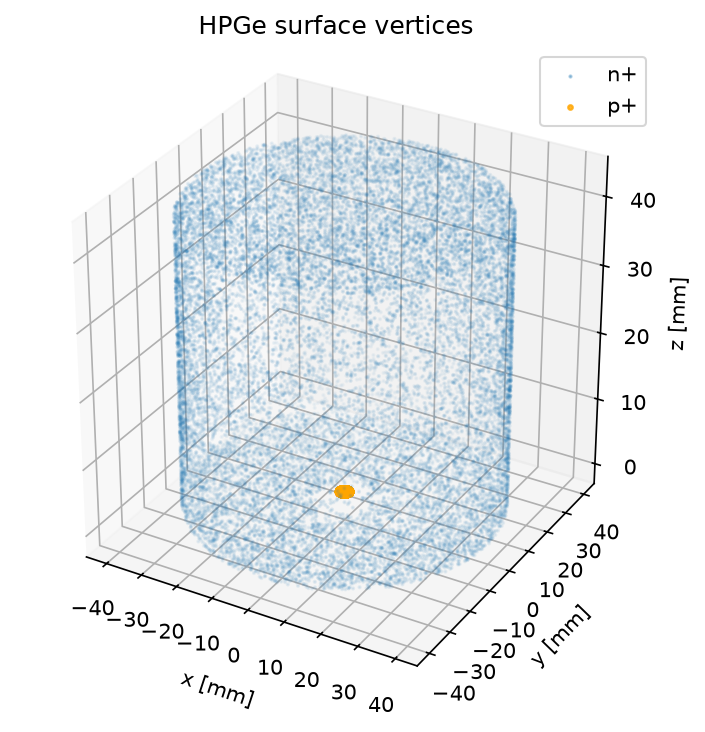

In [8]:
# ============================================================
# CHECK REVERTEX VERTICES
# ============================================================

verticesn_check = sample_hpge_surface(
    N_surf,
    seed=seed_vtx,
    hpges=hpge_pyobj,
    positions=position,
    surface_type="nplus"
)

verticesp_check = sample_hpge_surface(
    N_surf,
    seed=seed_vtx,
    hpges=hpge_pyobj,
    positions=position,
    surface_type="pplus"
)


# ============================================================
# SOTTOCAMPIONAMENTO
# ============================================================

nplot = min(20_000, N_surf)

rng = np.random.default_rng(123)

idx_n = rng.choice(
    len(verticesn_check),
    size=nplot,
    replace=False
)

idx_p = rng.choice(
    len(verticesp_check),
    size=nplot,
    replace=False
)

vtx_n = verticesn_check[idx_n]
vtx_p = verticesp_check[idx_p]


# ============================================================
# PLOT 3D n+ E p+
# ============================================================

fig = plt.figure(
    figsize=(6, 5),
    dpi=150
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# n+
ax.scatter(
    vtx_n[:, 0],
    vtx_n[:, 1],
    vtx_n[:, 2],
    s=1,
    alpha=0.35,
    label="n+"
)

# p+ in arancione
ax.scatter(
    vtx_p[:, 0],
    vtx_p[:, 1],
    vtx_p[:, 2],
    s=5,
    alpha=0.8,
    color="orange",
    label="p+"
)

ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_zlabel("z [mm]")

ax.set_title("HPGe surface vertices")

ax.set_box_aspect((1, 1, 1))

ax.legend()

plt.tight_layout()
plt.show()

In [10]:
N_sim = 50_000_000

macro = [
    "/RMG/Manager/Logging/LogLevel summary",

    "/RMG/Processes/HadronicPhysics Shielding",

    "/RMG/Geometry/RegisterDetector Germanium Bob 1",

    "/RMG/Output/NtupleUseVolumeName true",
    "/RMG/Output/NtuplePerDetector false",

    "/run/initialize",

    # genera uniformemente nel LAr
    "/RMG/Generator/Confine Volume",
    "/RMG/Generator/Confinement/Physical/AddVolume LAr",

    "/RMG/Generator/Select GPS",

    # 42K
    "/gps/particle ion",
    "/gps/ion 19 42",
    "/gps/energy 0 keV",

    f"/run/beamOn {N_sim}",
]

In [11]:
# con questo codice genero sia K42+ che K42-


N_surf = 1000000
# con questo codice genero SOLO  K42+
# ============================================================
# REMAGE MACRO
# ============================================================
macro_surface_n = [

    "/RMG/Manager/Logging/LogLevel summary",

    "/RMG/Processes/HadronicPhysics Shielding",

    "/RMG/Geometry/RegisterDetector Germanium Bob 1",

    "/RMG/Output/NtupleUseVolumeName true",
    "/RMG/Output/NtuplePerDetector false",

    # =========================
    # INIZIALIZZAZIONE PRIMA
    # =========================

    "/run/initialize",

    # =========================
    # VERTICI DA REVERTEX
    # =========================

    "/RMG/Generator/Confine FromFile",
    f"/RMG/Generator/Confinement/FromFile/FileName {vertexn_file}",

    # =========================
    # 42K+
    # =========================

    "/RMG/Generator/Select GPS",

    "/gps/particle ion",

    # Z=19, A=42, Q=+1, Eexc=0 keV
    "/gps/ion 19 42 1 0",

    "/gps/energy 0 keV",

    # =========================
    # RUN
    # =========================

    f"/run/beamOn {N_surf}",
]


In [12]:
# con questo codice genero sia K42+ che K42-


N_surf = 1000000
# con questo codice genero SOLO  K42+
# ============================================================
# REMAGE MACRO
# ============================================================
macro_surface_p = [

    "/RMG/Manager/Logging/LogLevel summary",

    "/RMG/Processes/HadronicPhysics Shielding",

    "/RMG/Geometry/RegisterDetector Germanium Bob 1",

    "/RMG/Output/NtupleUseVolumeName true",
    "/RMG/Output/NtuplePerDetector false",

    # =========================
    # INIZIALIZZAZIONE PRIMA
    # =========================

    "/run/initialize",

    # =========================
    # VERTICI DA REVERTEX
    # =========================

    "/RMG/Generator/Confine FromFile",
    f"/RMG/Generator/Confinement/FromFile/FileName {vertexp_file}",

    # =========================
    # 42K+
    # =========================

    "/RMG/Generator/Select GPS",

    "/gps/particle ion",

    # Z=19, A=42, Q=+1, Eexc=0 keV
    "/gps/ion 19 42 1 0",

    "/gps/energy 0 keV",

    # =========================
    # RUN
    # =========================

    f"/run/beamOn {N_surf}",
]


In [13]:
# ============================================================
# RUN REMAGE
# ============================================================

output_file = "K42_surface_nplus_HPGe.lh5"

force_run = False


simulation_ok = False


if force_run or not os.path.exists(output_file):

    try:

        remage_run(
            macros=macro_surface_n,
            gdml_files=gdml_file,
            output=output_file,
            overwrite_output=True
        )

        simulation_ok = True

        print(
            "✅ Simulazione 42K+ sulla n+ completata"
        )

    except Exception as e:

        print(
            f"❌ Simulation failed: {e}"
        )

else:

    simulation_ok = True

    print(
        f"✅ {output_file} già esistente, "
        "salto la simulazione"
    )

✅ K42_surface_nplus_HPGe.lh5 già esistente, salto la simulazione


# ============================================================
# RUN REMAGE
# ============================================================

output_file = "K42_surface_pplus_HPGe.lh5"

force_run = False


simulation_ok = False


if force_run or not os.path.exists(output_file):

    try:

        remage_run(
            macros=macro_surface_p,
            gdml_files=gdml_file,
            output=output_file,
            overwrite_output=True
        )

        simulation_ok = True

        print(
            "✅ Simulazione 42K+ sulla p+ completata"
        )

    except Exception as e:

        print(
            f"❌ Simulation failed: {e}"
        )

else:

    simulation_ok = True

    print(
        f"✅ {output_file} già esistente, "
        "salto la simulazione"
    )

In [14]:
output_file = "K42_LAr.lh5"
force_run = False   # True = forza una nuova simulazione

if force_run or not os.path.exists(output_file):

    try:
        remage_run(
            macros=macro,
            gdml_files="geometry_K42_LAr.gdml",
            output=output_file,
            overwrite_output=True
        )

        print("✅ Simulazione completata")

    except Exception as e:
        print(f"❌ Simulation failed: {e}")

else:

    print(f"✅ {output_file} già esistente, salto la simulazione")


data_bulk = lh5.read_as(
    "stp/germanium",
    output_file,
    "ak",
    with_units=True
)

✅ K42_LAr.lh5 già esistente, salto la simulazione


In [40]:
# posto prreocessing con reboost

import awkward as ak
import reboost
import numpy as np
from reboost import hpge
from reboost.hpge import surface, psd
from reboost.shape import group
from reboost.math import functions
from reboost.math.stats import gaussian_sample

import hist
import matplotlib.pyplot as plt

In [41]:
data = lh5.read_as(
    "stp/germanium",
    "K42_LAr.lh5",
    "ak"
)
data_surface_n = lh5.read_as(
    "stp/germanium",
    "K42_surface_nplus_HPGe.lh5",
    "ak"
)

In [42]:
print(f"Type of data: {ak.type(data)}")
print(f"Fields of data: {data.fields}")

Type of data: 578824 * {det_uid: var * int32, dist_to_surf: var * float64, edep: var * float64, evtid: int64, particle: var * int32, t0: float64, time: var * float64, xloc: var * float64, yloc: var * float64, zloc: var * float64}
Fields of data: ['det_uid', 'dist_to_surf', 'edep', 'evtid', 'particle', 't0', 'time', 'xloc', 'yloc', 'zloc']


In [43]:
print(f"Energy field shape: {ak.type(data.edep)}")
print(f"Energy field: {data.edep}")
print(f"Event id field: {data.evtid}")

Energy field shape: 578824 * var * float64
Energy field: [[0.0793, 0.1, 75, 278, 115, 15.5, ..., 67.7, 168, 295, 137, 57.4, 122], ...]
Event id field: [266, 293, 634, 650, 774, ..., 49999367, 49999646, 49999776, 49999788, 49999843]


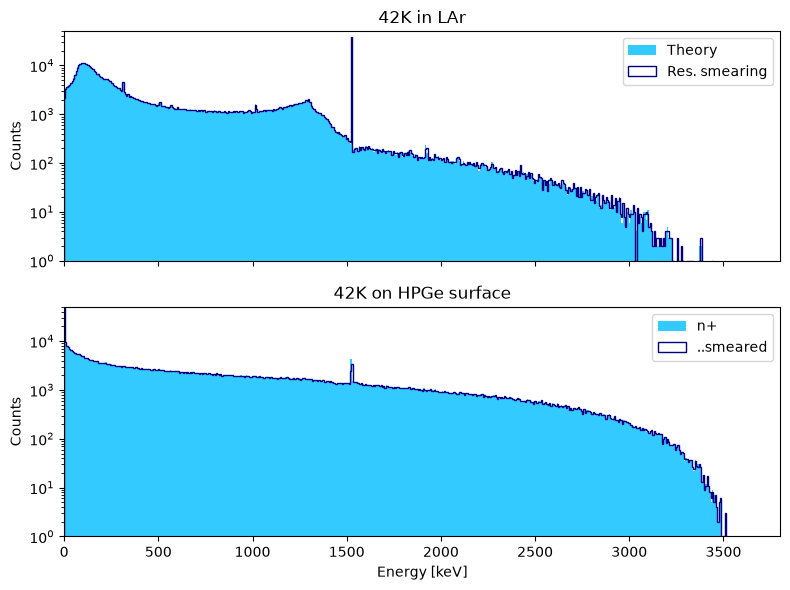

In [49]:
# =========================
# BULK LAr
# =========================

data_bulk = lh5.read_as(
    "stp/germanium",
    "K42_LAr.lh5",
    "ak"
)

energy_bulk = ak.sum(
    data_bulk.edep,
    axis=-1
)

energy_bulk_smeared = reboost.math.stats.gaussian_sample(
    energy_bulk,
    sigma=0.6
)


# =========================
# SURFACE HPGe n
# =========================

data_surface_n = lh5.read_as(
    "stp/germanium",
    "K42_surface_nplus_HPGe.lh5",
    "ak"
)

energy_surface_n = ak.sum(
    data_surface_n.edep,
    axis=-1
)

energy_surface_smeared_n = reboost.math.stats.gaussian_sample(
    energy_surface_n,
    sigma=0.6
)

# =========================
# SURFACE HPGe p
# =========================
'''
data_surface_p = lh5.read_as(
    "stp/germanium",
    "K42_surface_pplus_HPGe.lh5",
    "ak"
)

energy_surface_p = ak.sum(
    data_surface_p.edep,
    axis=-1
)

energy_surface_smeared_p = reboost.math.stats.gaussian_sample(
    energy_surface_p,
    sigma=0.6
)
'''
# =========================
# PLOT
# =========================

bins = 500

fig, ax = plt.subplots(
    2, 1,
    figsize=(8, 6),
    sharex=True
)

# --- BULK ---
ax[0].hist(
    energy_bulk,
    bins=bins,
    color="deepskyblue",
    alpha=0.8,
    label="Theory"
)

ax[0].hist(
    energy_bulk_smeared,
    bins=bins,
    color="navy",
    histtype="step",
    label="Res. smearing"
)

'''
ax[0].axvline(
    1524.6,
    color="orange",
    ls="--",
    label="1524.6 keV"
)
'''
ax[0].set_title("42K in LAr")
ax[0].set_ylabel("Counts")
ax[0].set_yscale("log")
ax[0].set_xlim(10, 3500)
ax[0].set_ylim(1, 5e4)
ax[0].legend()


# --- SURFACE ---
ax[1].hist(
    energy_surface_n,
    bins=bins,
    color="deepskyblue",
    alpha=0.8,
    label="n+"
)

ax[1].hist(
    energy_surface_smeared_n,
    bins=bins,
    color="navy",
    histtype="step",
    label="..smeared"
)
'''
ax[1].hist(
    energy_surface_p,
    bins=bins,
    color="orange",
    alpha=0.8,
    label="p+"
)

ax[1].hist(
    energy_surface_smeared_p,
    bins=bins,
    color="red",
    histtype="step",
    label="..smeared"
)

ax[1].axvline(
    1524.6,
    color="orange",
    ls="--",
    label="1524.6 keV"
)'''

ax[1].set_title("42K on HPGe surface")
ax[1].set_xlabel("Energy [keV]")
ax[1].set_ylabel("Counts")
ax[1].set_yscale("log")
ax[1].set_xlim(0, 3800)
ax[1].set_ylim(1, 5e4)
ax[1].legend()

plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# GEOMETRIA HPGe
# ============================================================

reg = pyg4ometry.gdml.Reader(
    "geometry_K42_LAr.gdml"
).getRegistry()

hpge_pyobj = hpges.make_hpge(
    bege_meta,
    registry=None
)

position = reg.physicalVolumeDict["Bob"].position.eval()


# ============================================================
# IMPOSTAZIONI
# ============================================================

nmax = 5000
rng = np.random.default_rng(42)

emin = 40
emax = 3500



In [20]:
# ============================================================
# FUNZIONE PER LEGGERE I DEPOSITI
# ============================================================

def load_deposits(filename):

    stp = lh5.read_as(
        "stp/germanium",
        filename,
        "ak",
        with_units=True
    )

    # Distanze dalla superficie (se ti servono dopo)
    dist_all = reboost.hpge.surface.distance_to_surface(
        stp.xloc,
        stp.yloc,
        stp.zloc,
        hpge_pyobj,
        position
    )

    dist_nplus = reboost.hpge.surface.distance_to_surface(
        stp.xloc,
        stp.yloc,
        stp.zloc,
        hpge_pyobj,
        position,
        surface_type="nplus"
    )

    # Coordinate dei depositi
    x = ak.to_numpy(ak.flatten(stp.xloc)) * 1000 - position[0]
    y = ak.to_numpy(ak.flatten(stp.yloc)) * 1000 - position[1]
    z = ak.to_numpy(ak.flatten(stp.zloc)) * 1000 - position[2]

    # Energia depositata
    edep = ak.to_numpy(
        ak.flatten(stp.edep)
    )

    # Taglio energetico
    mask = (
        (edep > emin) &
        (edep < emax)
    )

    x = x[mask]
    y = y[mask]
    z = z[mask]
    edep = edep[mask]

    # Sottocampionamento
    if len(x) > nmax:

        idx = rng.choice(
            len(x),
            size=nmax,
            replace=False
        )

        x = x[idx]
        y = y[idx]
        z = z[idx]
        edep = edep[idx]

    return x, y, z, edep, dist_all, dist_nplus


In [38]:

# ============================================================
# BULK LAr
# ============================================================

x_bulk, y_bulk, z_bulk, e_bulk, dist_bulk, dist_nplus_bulk = load_deposits(
    "K42_LAr.lh5"
)


# ============================================================
# SURFACE HPGe
# ============================================================

x_surfacen, y_surfacen, z_surfacen, e_surfacen, dist_surfacen, dist_nplus_surfacen = load_deposits(
    "K42_surface_nplus_HPGe.lh5"
)
'''
x_surfacep, y_surfacep, z_surfacep, e_surfacep, dist_surfacep, dist_nplus_surfacep = load_deposits(
    "K42_surface_pplus_HPGe.lh5"
)'''

NameError: name 'load_deposits' is not defined

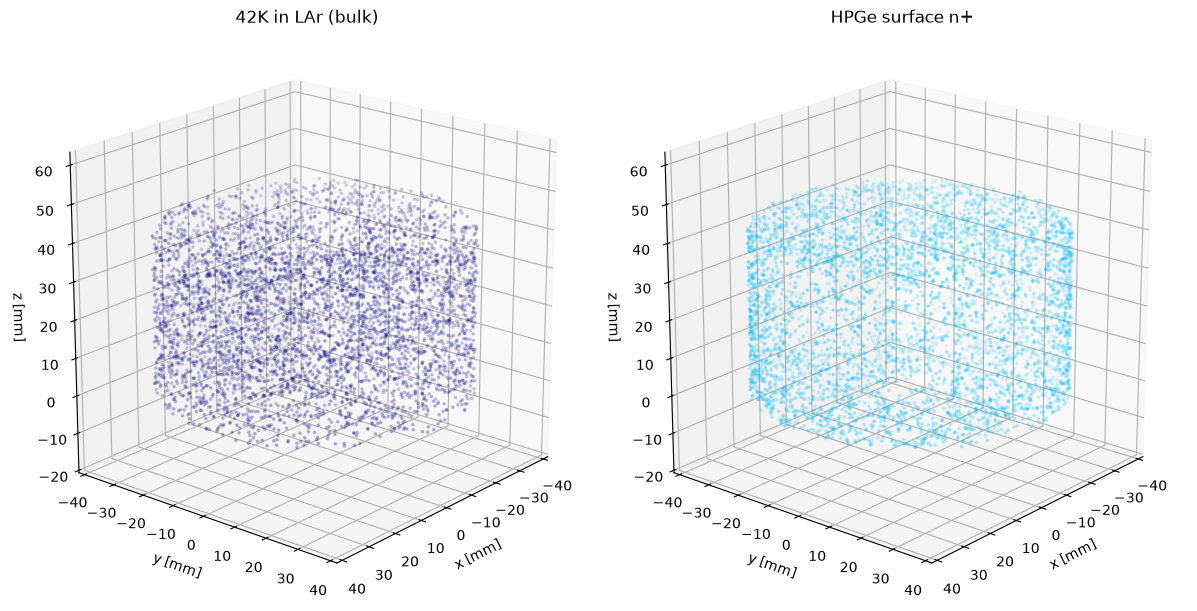

In [113]:
# ============================================================
# LIMITI COMUNI
# ============================================================

all_x = np.concatenate([x_bulk, x_surfacen,])
all_y = np.concatenate([y_bulk, y_surfacen,])
all_z = np.concatenate([z_bulk, z_surfacen])

# Usa 2 per includere l'intera estensione dei punti.
half_range = max(np.ptp(all_x), np.ptp(all_y), np.ptp(all_z)) / 2
half_range *= 1.05  # piccolo margine

mid_x = (all_x.max() + all_x.min()) / 2
mid_y = (all_y.max() + all_y.min()) / 2
mid_z = (all_z.max() + all_z.min()) / 2

# ============================================================
# TRE SUBPLOT ORIZZONTALI
# ============================================================

fig = plt.figure(figsize=(18, 6))

datasets = [
    (x_bulk,     y_bulk,     z_bulk,     "42K in LAr (bulk)", "navy"),
    (x_surfacen, y_surfacen, z_surfacen, "HPGe surface n+",   "deepskyblue"),
   # (x_surfacep, y_surfacep, z_surfacep, "HPGe surface p+",   "orange"),
]

for i, (x, y, z, title, color) in enumerate(datasets, start=1):
    ax = fig.add_subplot(1, 3, i, projection="3d")

    ax.scatter(
        x, y, z,
        color=color,
        s=3,
        alpha=0.5,
        rasterized=True
    )

    ax.set_title(title)
    ax.set_xlabel("x [mm]")
    ax.set_ylabel("y [mm]")
    ax.set_zlabel("z [mm]")

    ax.set_xlim(mid_x - half_range, mid_x + half_range)
    ax.set_ylim(mid_y - half_range, mid_y + half_range)
    ax.set_zlim(mid_z - half_range, mid_z + half_range)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=20, azim=40)

plt.tight_layout()
plt.show()

In [114]:
bin_edges = np.linspace(0, 3500, 350)
print(bin_edges[1]-bin_edges[0])

10.02865329512894


10.02865329512894


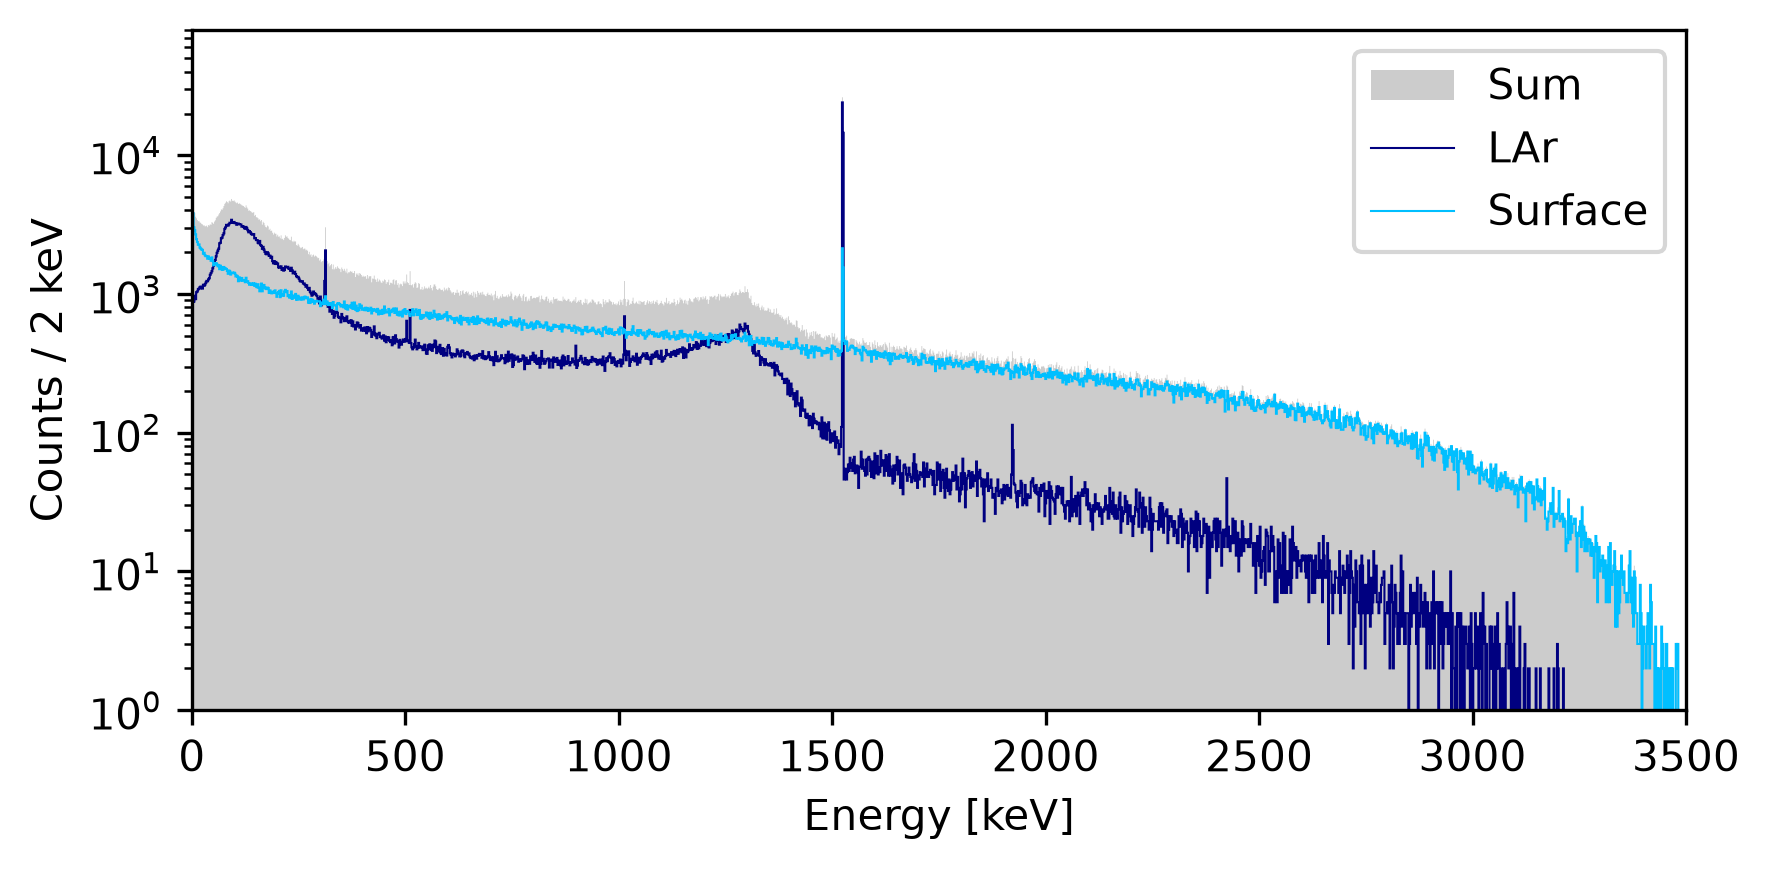

In [52]:
# somma degli spettri
# Numero di decadimenti effettivamente simulati
N_sim = 10
N_bulk = N_sim          # eventi bulk simulati
#N_surface = N_surf      # eventi surface simulati
bin_edges = np.linspace(0, 3500, 350)
print(bin_edges[1]-bin_edges[0])
# ============================
# Energia totale depositata per evento
# ============================
energy_bulk = ak.to_numpy(
    ak.sum(data_bulk.edep, axis=-1)
)

energy_surface = ak.to_numpy(
    ak.sum(data_surface_n.edep, axis=-1)
)

# ============================
# Smearing energetico (risoluzione)
# ============================
energy_bulk_smeared = ak.to_numpy(
    reboost.math.stats.gaussian_sample(
        energy_bulk,
        sigma = 0.6
    )
)

energy_surface_smeared = ak.to_numpy(
    reboost.math.stats.gaussian_sample(
        energy_surface,
        sigma = 0.6
    )
)

# ============================
# Bin comuni
# ============================
bg = np.linspace(0, 3500, 1750)

# ============================
# Pesi corretti
# ============================
# Bulk: nessun peso → già rappresenta N_bulk eventi
weights_bulk = np.ones_like(energy_bulk_smeared)

# Surface: ogni evento deve valere N_bulk / N_surface
weights_surface = np.full(
    len(energy_surface_smeared),
    1
)

# ============================
# Istogrammi
# ============================
h_bulk, _ = np.histogram(
    energy_bulk_smeared,
    bins = bg,
    #weights = weights_bulk
)

h_surface, _ = np.histogram(
    energy_surface_smeared,
    bins = bg,
    #weights = weights_surface
)

# ============================
# Somma dei contributi
# ============================
h_sum = h_bulk + h_surface
N_sim = 10
# ============================
# Centri dei bin
# ============================
bin_centers = 0.5 * (bg[:-1] + bg[1:])
# Centri dei bin
# Plot
plt.figure(figsize=(6, 3), dpi = 300)

# Spettri con plt.step
plt.stairs(
    h_sum,
    bg,
    color='grey',
    fill = True,
    label="Sum",
    alpha =0.4
)

plt.stairs(
    h_bulk,
    bg,
    color='navy',
    label="LAr",
    linewidth = 0.5,
    #alpha=0.7,
)

plt.stairs(
    h_surface,
    bg,
    color='deepskyblue',
    label="Surface",
    linewidth = 0.5
    #alpha=0.7,
)





'''
plt.axvline(
    1524.6,
    ls="--",
    color = 'orange',
    label="1524.6 keV"
)'''
plt.xlim(0, 3500)
plt.ylim(1, 8e4)
plt.yscale("log")

plt.xlabel("Energy [keV]")
plt.ylabel(f"Counts / {bg[1]-bg[0]:.0f} keV")

plt.legend()
plt.tight_layout()
plt.show()

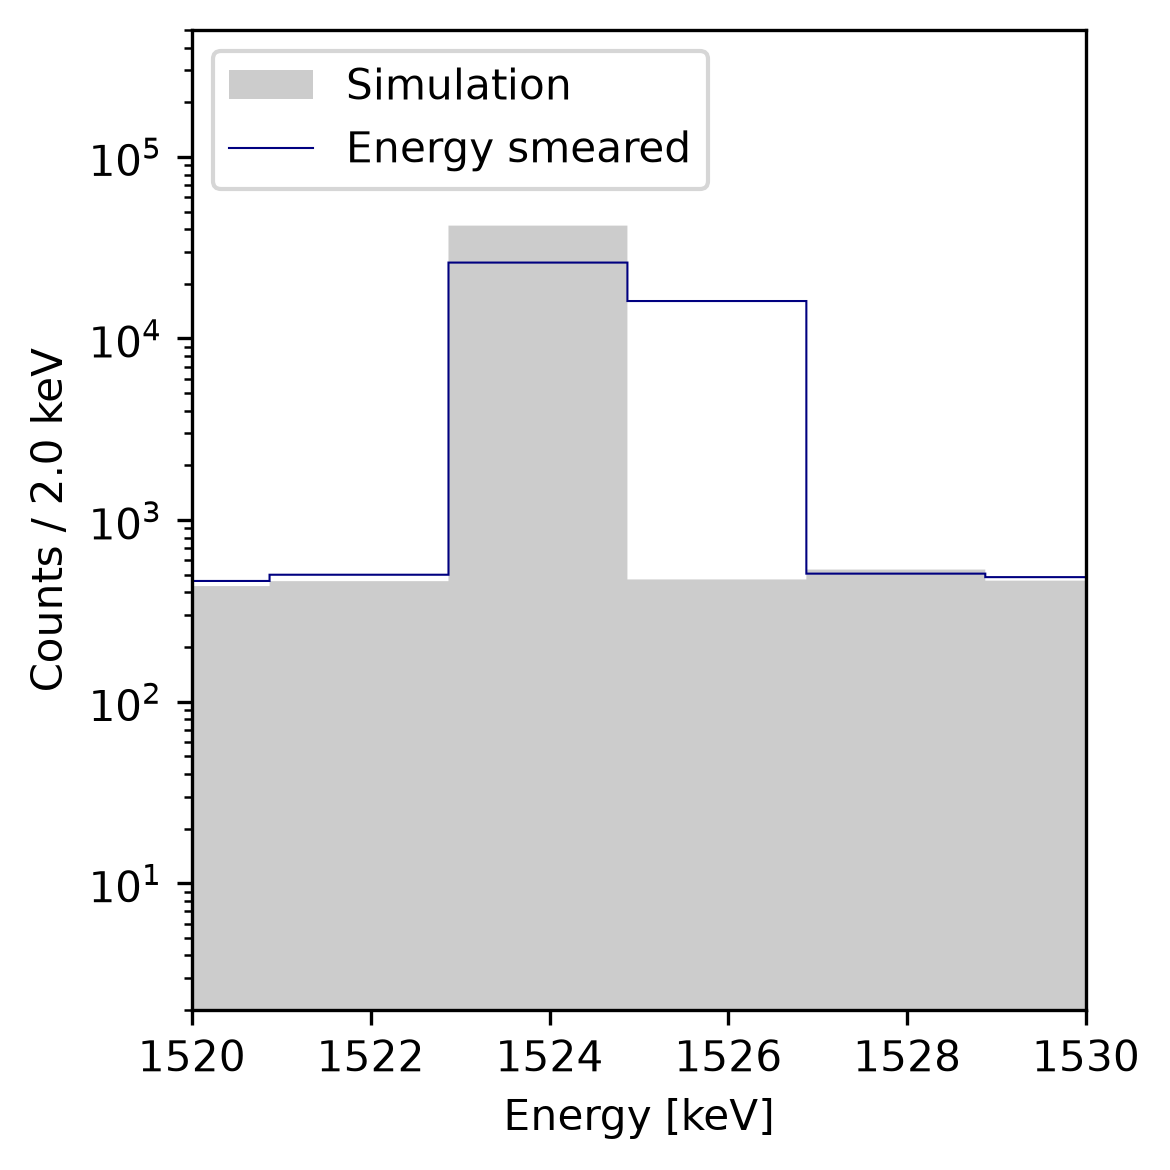

In [53]:

# ============================
# Istogrammi
# ============================
h_bulk_theo, _ = np.histogram(
    energy_bulk,
    bins = bg,
    #weights = weights_bulk
)

h_surface_theo, _ = np.histogram(
    energy_surface,
    bins = bg,
    #weights = weights_surface
)

# ============================
# Somma dei contributi
# ============================
h_sum = h_bulk + h_surface
h_sum_theo = h_bulk_theo + h_surface_theo

# ============================
# Centri dei bin
# ============================
bin_centers = 0.5 * (bg[:-1] + bg[1:])
# Centri dei bin
# Plot
plt.figure(figsize=(4, 4), dpi = 300)

# Spettri con plt.step
plt.stairs(
    h_sum_theo,
    bg,
    color='grey',
    fill = True,
    label="Simulation",
    alpha =0.4
)

plt.stairs(
    h_sum,
    bg,
    color='navy',
    label="Energy smeared",
    linewidth = 0.5,
    #alpha=0.7,
)
#plt.vlines(1524.75, 1, 5e8 , color = 'orange', ls = '--')
plt.xlim(1520, 1530)
plt.ylim(2, 5e5)
plt.yscale("log")

plt.xlabel("Energy [keV]")
plt.ylabel(f"Counts / {bg[1]-bg[0]:.1f} keV")

plt.legend(loc = 'upper left')
plt.tight_layout()
plt.show()

# inizio studio delle sistematiche

In [14]:
import simulate_CCE_Li_radii
importlib.reload(simulate_CCE_Li_radii)

--------------------------------
CCE simulation
--------------------------------
seed = 1
--------------------------------


<module 'simulate_CCE_Li_radii' from '/global/u2/r/ritaferi/CTM/CCE_study/simulate_CCE_Li_radii.py'>

## FCCD

In [10]:
def CCE_func(d_mm):
        mean = cce_interp(d_mm)
        std = cce_std_interp(d_mm)
    
        # Random uniforme tra -1 e +1
        random_factor = np.random.uniform(
            -1.0,
            1.0,
            size=np.asarray(d_mm).shape
        )
    
        cce_random = mean + random_factor * std
    
        return np.clip(
            cce_random,
            0.0,
            1.0
        )

In [11]:
def make_spectrum(data, cce_interp, cce_std_interp):

    # -----------------------------------------
    # Distanza dalla superficie per ogni step
    # -----------------------------------------
    dist_flat_mm = (
        ak.to_numpy(
            ak.flatten(data.dist_to_surf)
        ) * 1000.0
    )

    event_sizes = ak.num(data.dist_to_surf)

    # -----------------------------------------
    # CCE media + smearing CCE
    # -----------------------------------------
    mean = cce_interp(dist_flat_mm)
    std = cce_std_interp(dist_flat_mm)

    # Smearing fisico della CCE
    random_factor = np.random.uniform(
        -1.0,
        1.0,
        size=dist_flat_mm.shape
    )

    cce_random = np.clip(
        mean + random_factor * std,
        0.0,
        1.0
    )

    charge_collection_eff = ak.unflatten(
        cce_random,
        event_sizes
    )

    # -----------------------------------------
    # Energia raccolta per evento
    # -----------------------------------------
    energy = ak.sum(
        data.edep * charge_collection_eff,
        axis=-1
    )

    # -----------------------------------------
    # Smearing risoluzione energetica
    # -----------------------------------------
    energy_smeared = reboost.math.stats.gaussian_sample(
        energy,
        sigma=0.6
    )

    return ak.to_numpy(energy_smeared)


In [12]:
def make_spectrum(data, cce_interp, cce_std_interp):

    # -----------------------------------------
    # Distanza dalla superficie per ogni step
    # -----------------------------------------
    dist_flat_mm = (
        ak.to_numpy(
            ak.flatten(data.dist_to_surf)
        ) * 1000.0
    )

    event_sizes = ak.num(data.dist_to_surf)


    # -----------------------------------------
    # CCE media + smearing CCE
    # -----------------------------------------
    mean = cce_interp(dist_flat_mm)
    std = cce_std_interp(dist_flat_mm)

    random_factor = np.random.uniform(
        -1.0,
        1.0,
        size=dist_flat_mm.shape
    )
    '''
    cce_random = np.clip(
        mean + random_factor * std,
        0.0,
        1.0
    )'''

    cce_random  = mean

    charge_collection_eff = ak.unflatten(
        cce_random,
        event_sizes
    )


    # -----------------------------------------
    # Energia raccolta per evento
    # -----------------------------------------
    energy = ak.sum(
        data.edep * charge_collection_eff,
        axis=-1
    )


    # -----------------------------------------
    # Smearing risoluzione energetica
    # -----------------------------------------
    energy_smeared = reboost.math.stats.gaussian_sample(
        energy,
        sigma=0.6
    )

    return ak.to_numpy(energy_smeared)

Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 180458.97it/s]


0.002 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 268.23it/s]



Total theoretical primary Li (R=20 um) = 12355
Total theoretical agglomerates = 560
Total theoretical remaining 20 um particles = 695
Total accepted agglomerates = 542
Total accepted remaining 20 um particles = 695
Total accepted Li particles = 1237

Starting CCE simulation...



CCE depth: 100%|██████████| 23/23 [01:47<00:00,  4.69s/it]


Text(-8.58333333333334, 0.5, 'CCE')

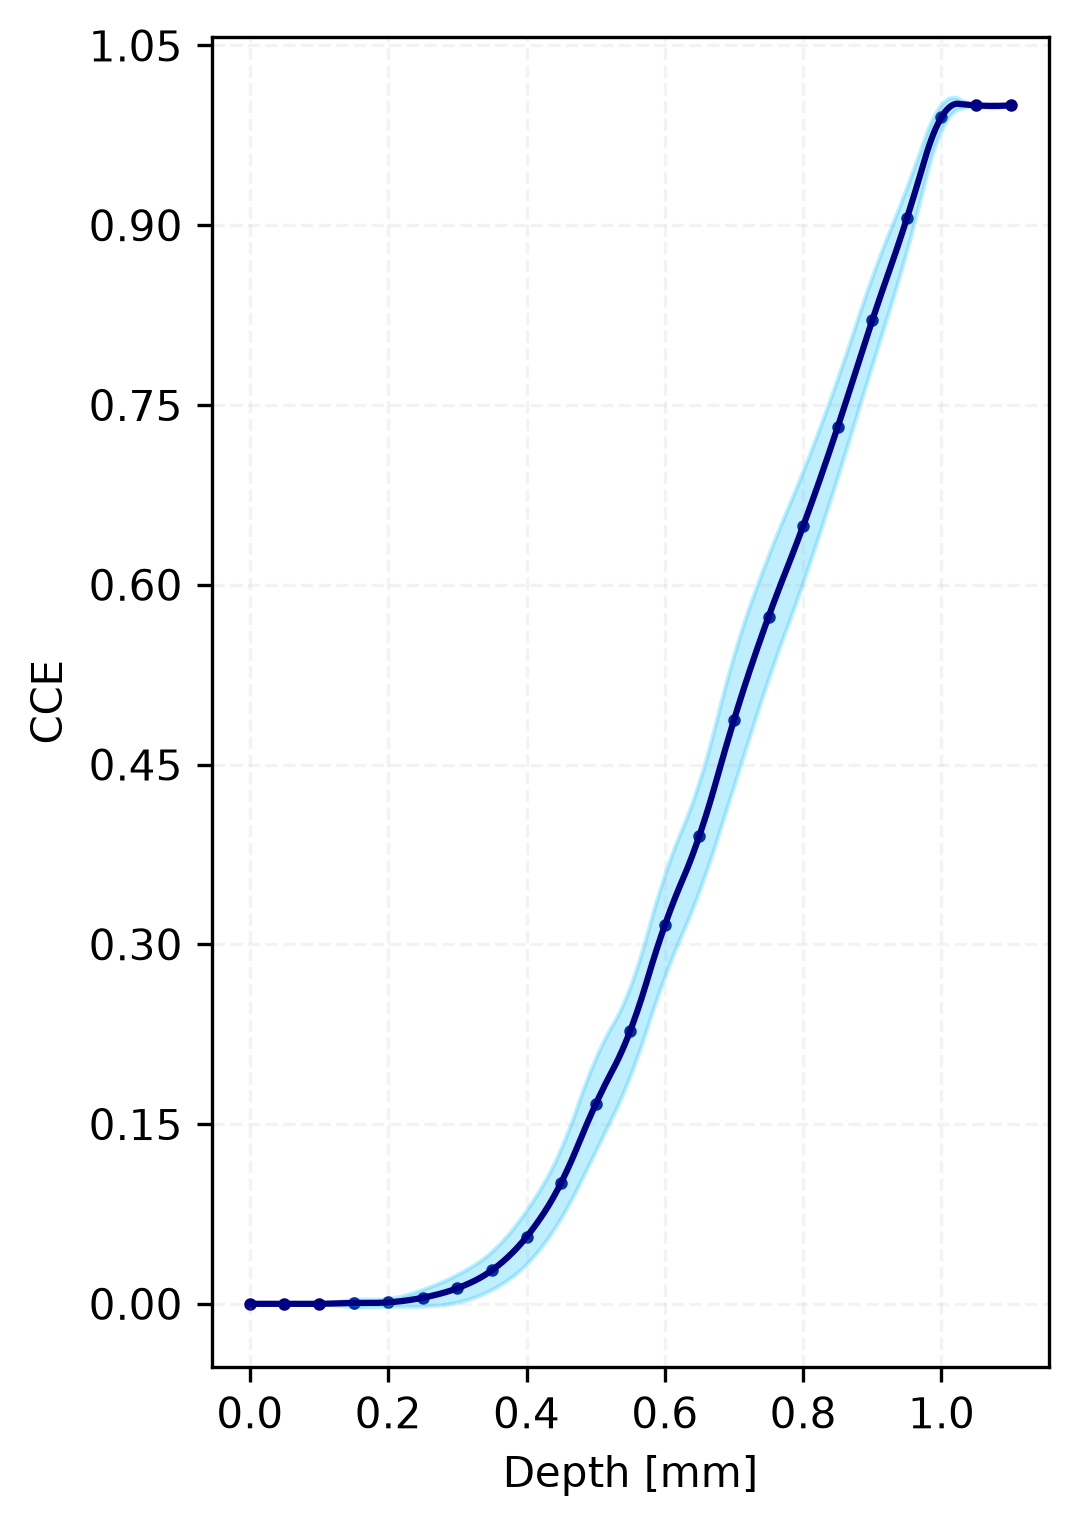

In [48]:
FCCD = 0.1
FCCD_um = FCCD * 1e4


fig, ax = plt.subplots(
    figsize=( 3.5, 5),
    dpi=300
)

my_args = argparse.Namespace(
        seed=int(123),
        N_charges=100,
        N_repeat=100,
        alpha=1.6e-10,
        FCCD=FCCD,
        sigma_R=0.002,
        N_sat=1e14,
        T_ann=623,   # 350 gradi
        t_ann=18*60,   # 18 minuti ore
        output="library"
    )

params = simulate_CCE_Li_radii.update_parameters(my_args)

cells, saturation_depth, px, py, pz, particles_R, lithium_distribution = (
        simulate_CCE_Li_radii.generate_lithium(params)
    )

x, CCE_matrix, CCE_mean, CCE_std = (
        simulate_CCE_Li_radii.simulate_CCE(
            cells,
            saturation_depth,
            px,
            py,
            pz,
            particles_R,
            my_args
        )
    )

CCE_min = np.min(CCE_matrix, axis=1)
CCE_max = np.max(CCE_matrix, axis=1)

cce_min = np.array(CCE_min)
cce_max = np.array(CCE_max)

    # INTERPOLATION
depth = np.array(x) * 10
cce = CCE_mean
cce_std = CCE_std

cce_interp = interp1d(
        depth,
        cce,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce[0], 1.0)
    )

cce_min_interp = interp1d(
        depth,
        cce_min,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_min[0], 1.0)
    )

cce_max_interp = interp1d(
        depth,
        cce_max,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_max[0], 1.0)
    )

cce_std_interp = interp1d(
        depth,
        cce_std,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_std[0], cce_std[-1])
    )

depth_fine = np.linspace(
        depth.min(),
        1.1,
        500
    )

cce_fine = cce_interp(depth_fine)
cce_std_fine = cce_std_interp(depth_fine)

ax.scatter(depth,
        cce,
          color = 'navy',
          s = 4)
ax.plot(
        depth_fine,
        cce_fine,
        color="navy"
    )

ax.fill_between(
        depth_fine,
        cce_fine - cce_std_fine,
        cce_fine + cce_std_fine,
        color='deepskyblue',
        alpha=0.25
    )
from matplotlib.ticker import MaxNLocator

ax.xaxis.set_major_locator(MaxNLocator(nbins=8))
ax.yaxis.set_major_locator(MaxNLocator(nbins=10))
fig.tight_layout()
plt.grid(alpha = 0.15, ls = '--')

ax.set_xlabel("Depth [mm]")
ax.set_ylabel("CCE")


In [55]:
FCCDs = np.arange(600, 1400, 200) / 10000
len(FCCDs)

4

Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 172799.04it/s]


0.001 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 3273.85it/s]



Total theoretical primary Li (R=20 um) = 3154
Total theoretical agglomerates = 422
Total theoretical remaining 20 um particles = 168
Total accepted agglomerates = 422
Total accepted remaining 20 um particles = 168
Total accepted Li particles = 590
FCCD = 600.0 um
seed = 123
Numero Li: 590
Profondità saturazione: 0.66 mm

Starting CCE simulation...



CCE depth: 100%|██████████| 15/15 [00:55<00:00,  3.72s/it]


...

Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 194535.53it/s]


0.001 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 3427.40it/s]



Total theoretical primary Li (R=20 um) = 3080
Total theoretical agglomerates = 395
Total theoretical remaining 20 um particles = 174
Total accepted agglomerates = 395
Total accepted remaining 20 um particles = 174
Total accepted Li particles = 569
FCCD = 1400.0000000000002 um
seed = 123
Numero Li: 569
Profondità saturazione: 0.66 mm

Starting CCE simulation...



CCE depth: 100%|██████████| 32/32 [07:46<00:00, 14.57s/it]


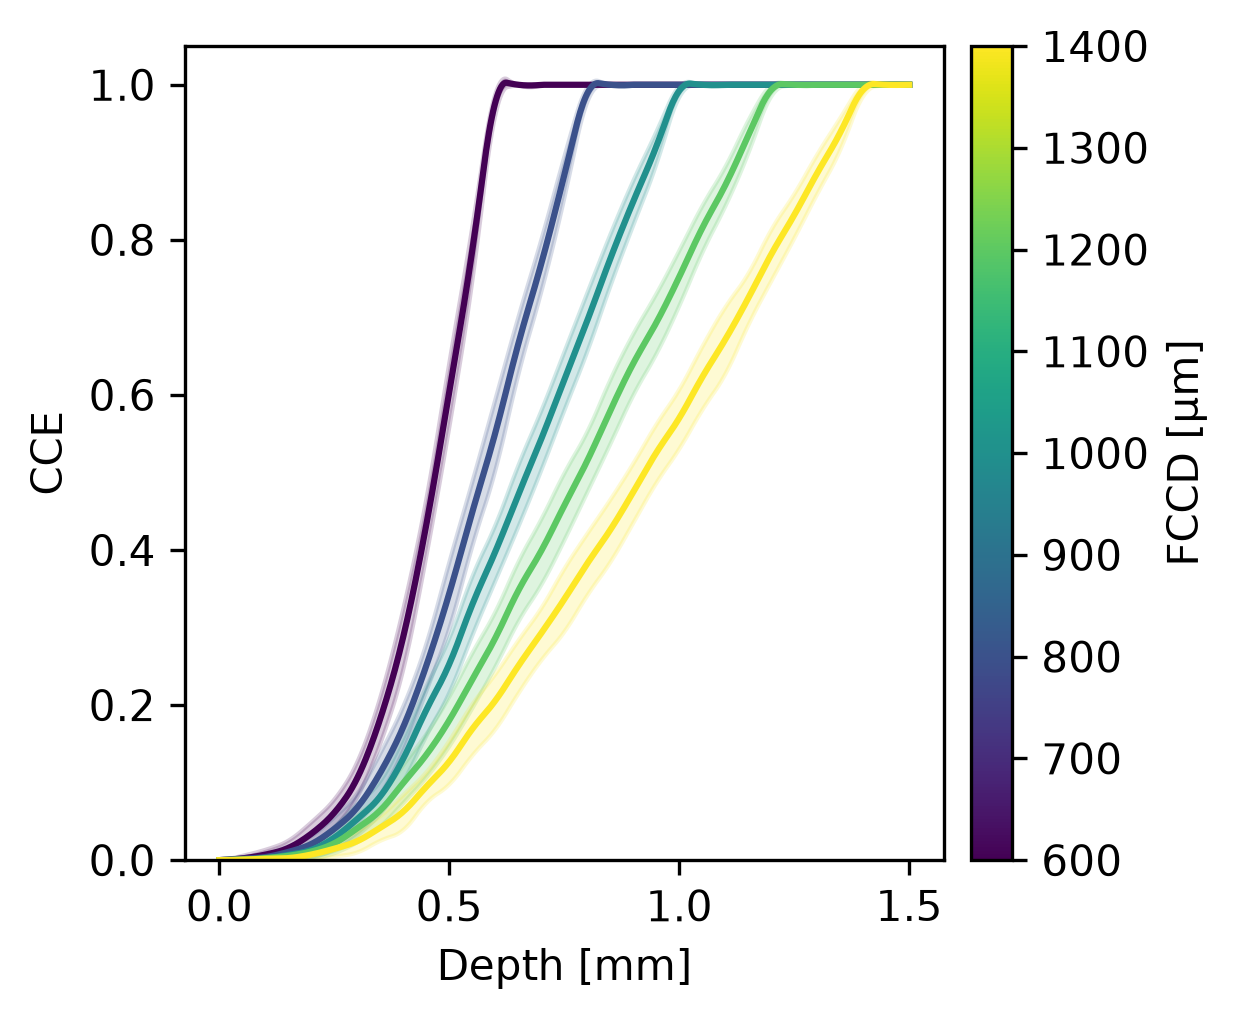

In [57]:
FCCDs = np.arange(600, 1401, 200) / 10000
FCCD_um = FCCDs * 1e4

cmap = plt.colormaps["viridis"]

norm = mpl.colors.Normalize(
    vmin=FCCD_um.min(),
    vmax=FCCD_um.max()
)

histograms = {}
CCE_dict = {}

fig, ax = plt.subplots(
    figsize=(4.2, 3.5),
    dpi=300
)

for i, FCCD in enumerate(FCCDs):

    my_args = argparse.Namespace(
        seed=int(123),
        N_charges=150,
        N_repeat=150,
        alpha=4e-11,
        FCCD=FCCD,
        sigma_R=0.001,
        N_sat=1e14,
        T_ann=623,   # 350 gradi
        t_ann=18*60,   # 18 minuti ore
        output="library"
    )

    params = simulate_CCE_Li_radii.update_parameters(my_args)

    cells, saturation_depth, px, py, pz, particles_R, lithium_distribution = (
        simulate_CCE_Li_radii.generate_lithium(params)
    )

    print("FCCD =", FCCD * 1e4, "um")
    print("seed =", my_args.seed)
    print("Numero Li:", len(px))
    print("Profondità saturazione:", saturation_depth * 10, "mm")

    x, CCE_matrix, CCE_mean, CCE_std = (
        simulate_CCE_Li_radii.simulate_CCE(
            cells,
            saturation_depth,
            px,
            py,
            pz,
            particles_R,
            my_args,
        )
    )

    CCE_min = np.min(CCE_matrix, axis=1)
    CCE_max = np.max(CCE_matrix, axis=1)

    cce_min = np.array(CCE_min)
    cce_max = np.array(CCE_max)

    # INTERPOLATION
    depth = np.array(x) * 10
    cce = CCE_mean
    cce_std = CCE_std

    cce_interp = interp1d(
        depth,
        cce,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce[0], 1.0)
    )

    cce_min_interp = interp1d(
        depth,
        cce_min,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_min[0], 1.0)
    )

    cce_max_interp = interp1d(
        depth,
        cce_max,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_max[0], 1.0)
    )

    cce_std_interp = interp1d(
        depth,
        cce_std,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_std[0], cce_std[-1])
    )

    depth_fine = np.linspace(
        depth.min(),
        1.5,
        500
    )

    cce_fine = cce_interp(depth_fine)
    cce_std_fine = cce_std_interp(depth_fine)

    # Colore associato direttamente alla FCCD
    color = cmap(
        norm(FCCD * 1e4)
    )

    ax.plot(
        depth_fine,
        cce_fine,
        color=color
    )

    ax.fill_between(
        depth_fine,
        cce_fine - cce_std_fine,
        cce_fine + cce_std_fine,
        color=color,
        alpha=0.2
    )

    # =========================
    # SPECTRA
    # =========================

    energy_bulk = make_spectrum(
        data_bulk,
        cce_interp,
        cce_std_interp
    )

    energy_surface = make_spectrum(
        data_surface_n,
        cce_interp,
        cce_std_interp
    )

    #bg = np.linspace(0, 3500, 350)
    bin_edges = np.linspace(0, 3500, 1750)

    counts_bulk, _ = np.histogram(
        energy_bulk,
        bins=bin_edges
    )


    
    counts_surface, _ = np.histogram(
        energy_surface,
        bins=bin_edges
    )

    N_bulk = N_sim
    N_surface = 15000

    spectrum_bulk =  counts_bulk #* N_surface / N_bulk

    spectrum_surface = counts_surface #* N_bulk / N_surface

    spectrum_tot = spectrum_bulk +spectrum_surface
    
    histograms[FCCD] = (
        spectrum_tot,
        bin_edges
    )

    CCE_dict[FCCD] = (
        depth_fine,
        cce_fine
    )


# ============================================================
# COLORBAR
# ============================================================

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.03
)

cbar.set_label("FCCD [μm]")


# ============================================================
# AXES
# ============================================================

ax.set_xlabel("Depth [mm]")
ax.set_ylabel("CCE")

ax.set_ylim(0, 1.05)

fig.tight_layout()

plt.show()


2.0011435105774726
2.0011435105774726


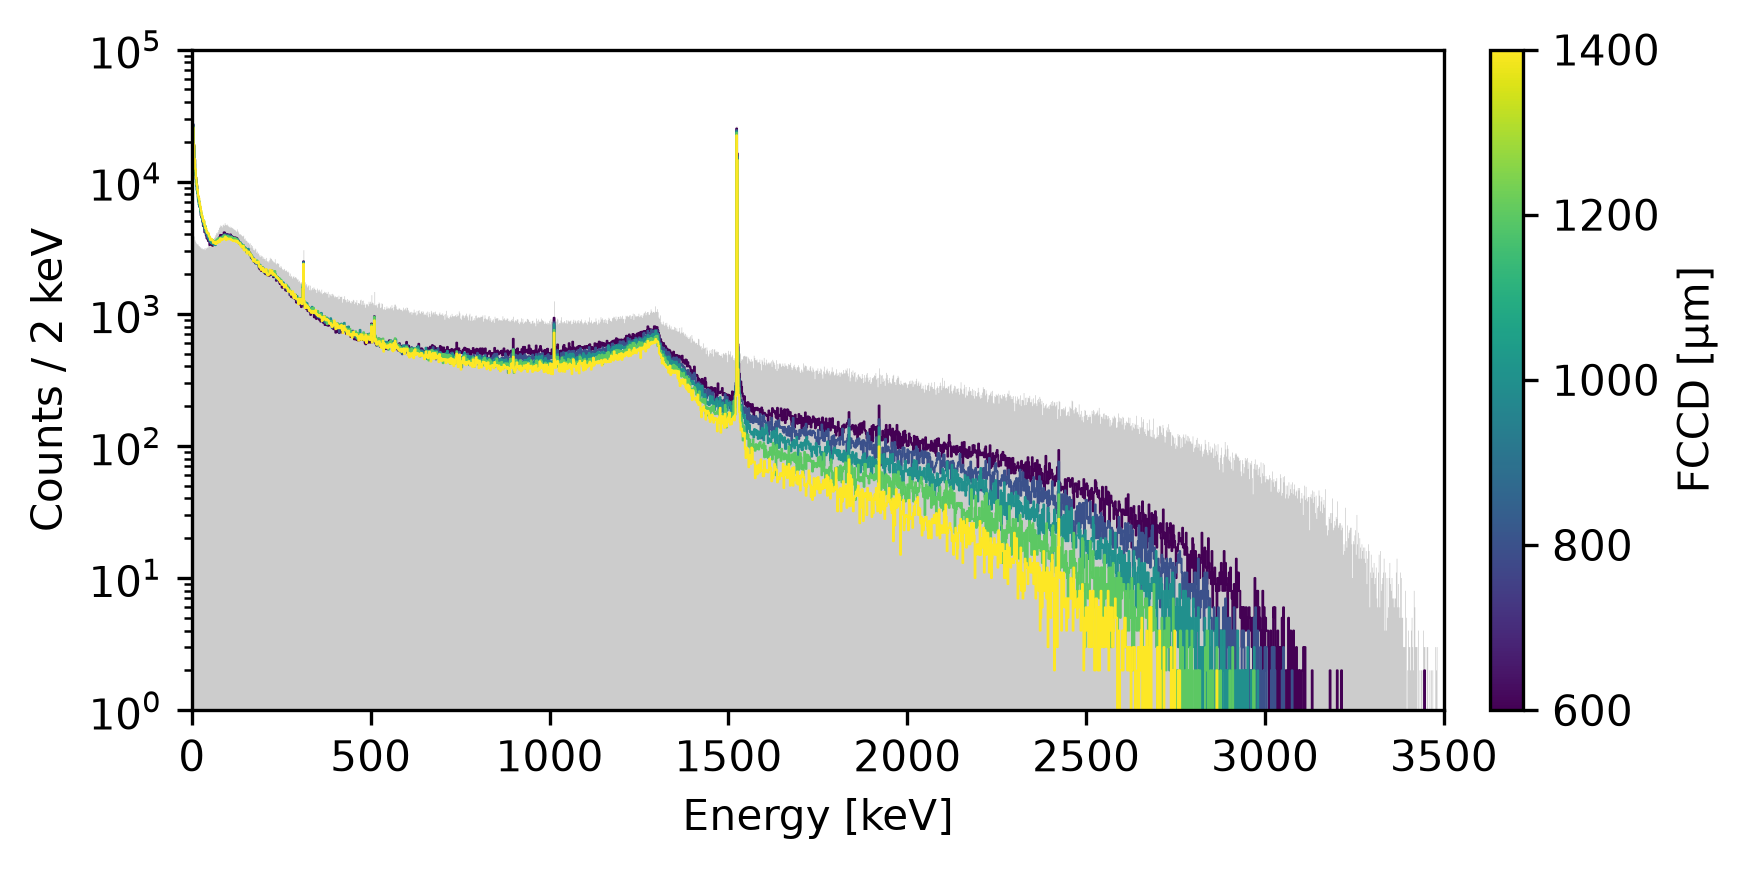

In [62]:
import matplotlib as mpl

fig, ax = plt.subplots(
    figsize=(6, 3),
    dpi=300
)

# ============================================================
# COLORMAP FCCD
# ============================================================

FCCD_um = FCCDs * 1e4

cmap = plt.colormaps["viridis"]

norm = mpl.colors.Normalize(
    vmin=FCCD_um.min(),
    vmax=FCCD_um.max()
)


# ============================================================
# SPETTRI TOTALI PER FCCD
# ============================================================

for FCCD, (counts, edges) in histograms.items():

    color = cmap(
        norm(FCCD * 1e4)
    )

    ax.step(
        edges[:-1],
        counts,
        where="mid",
        color=color,
        linewidth=0.5
    )


print(edges[1]-edges[0])
print(bg[1]-bg[0])

# ============================================================
# COLORBAR
# ============================================================

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.03
)

cbar.set_label("FCCD [μm]")

plt.stairs(
    h_sum,
    bg,
    fill = True,
    label="LAr + surface",
    color = 'grey',
    alpha = 0.4)


# ============================================================
# PLOT SETTINGS
# ============================================================
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ============================================================
# INSET ZOOM AROUND 1525 keV
# ============================================================
'''
axins = inset_axes(
    ax,
    width=1.25,   # dimensione relativa
    height=1.25,
    loc="upper right"
)

# Range di zoom
E_min = 1500
E_max = 1575

# Plot degli spettri FCCD dentro lo zoom
for FCCD, (counts, edges) in histograms.items():
    color = cmap(norm(FCCD * 1e4))
    axins.step(
        edges[:-1],
        counts,
        where="mid",
        color=color,
        linewidth=1.0
    )



# Impostazioni zoom
axins.set_xlim(E_min, E_max)
axins.set_ylim(100, 9e4)   # puoi adattarlo se vuoi
axins.set_yscale("log")

#axins.set_xticks([1500, 1525, 1550, 1570])


'''
ax.set_yscale("log")

ax.set_xlabel("Energy [keV]")
ax.set_ylabel(f"Counts / {bg[1]-bg[0]:.0f} keV")
ax.set_ylim(1, 1e5)
ax.set_xlim(0, 3500)
fig.tight_layout()

plt.show()

# sigma

Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 180341.41it/s]


0.0001 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 5895.77it/s]



Total theoretical primary Li (R=20 um) = 3139
Total theoretical agglomerates = 247
Total theoretical remaining 20 um particles = 119
Total accepted agglomerates = 247
Total accepted remaining 20 um particles = 119
Total accepted Li particles = 366
sigma = 1.0 um
seed = 123
Numero Li: 366
Profondità saturazione: 0.66 mm

Starting CCE simulation...



CCE depth: 100%|██████████| 23/23 [02:56<00:00,  7.66s/it]


...

Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 190913.15it/s]


0.01 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 1808.96it/s]



Total theoretical primary Li (R=20 um) = 3022
Total theoretical agglomerates = 759
Total theoretical remaining 20 um particles = 91
Total accepted agglomerates = 759
Total accepted remaining 20 um particles = 91
Total accepted Li particles = 850
sigma = 100.0 um
seed = 123
Numero Li: 850
Profondità saturazione: 0.66 mm

Starting CCE simulation...



CCE depth: 100%|██████████| 23/23 [05:13<00:00, 13.62s/it]


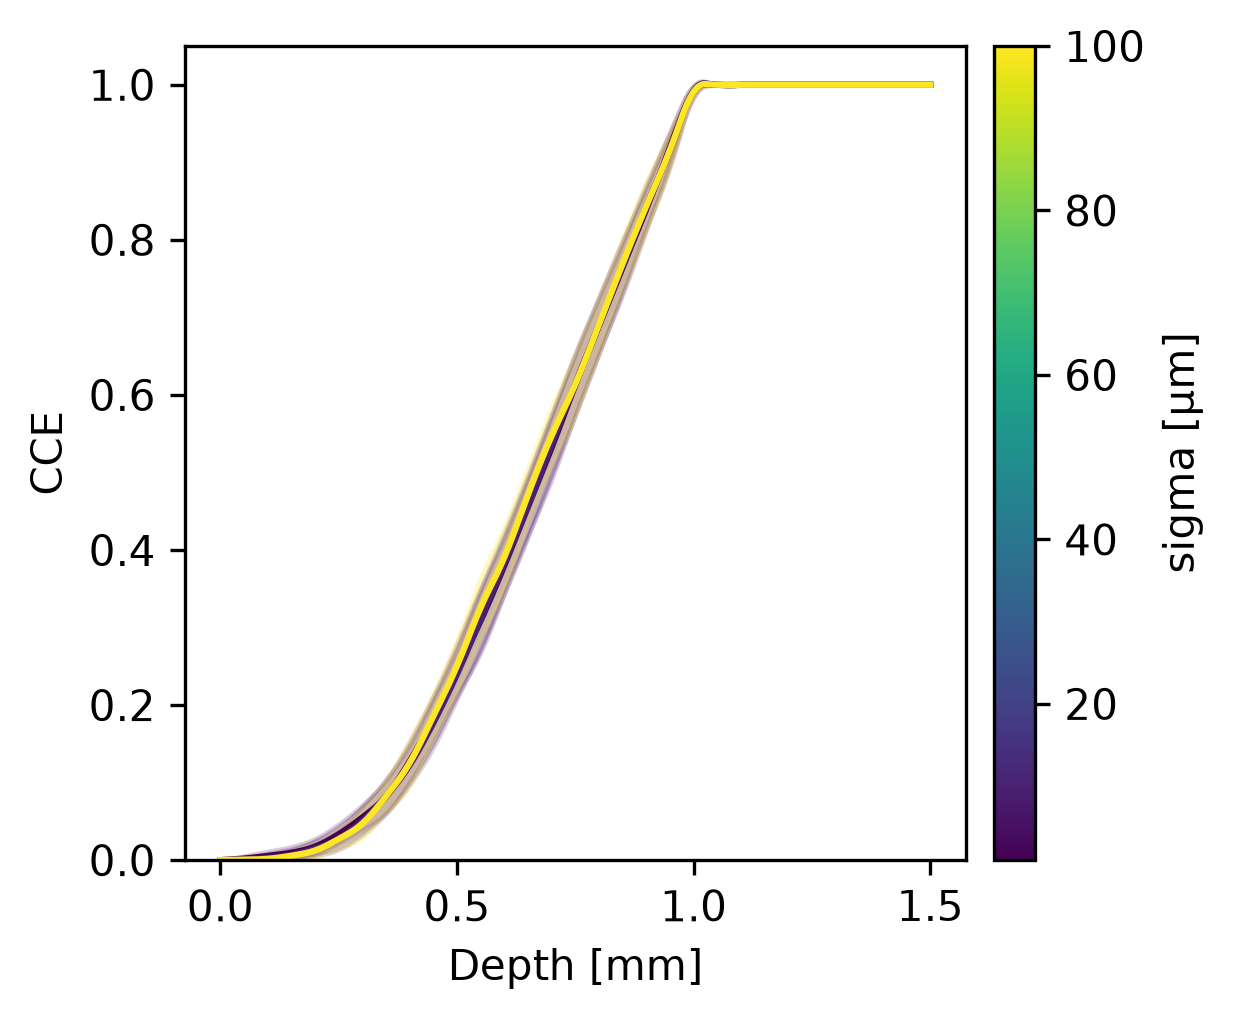

In [65]:
sigmas = np.array([0.0001, 0.001, 0.01])
sigmas_um = sigmas * 1e4

cmap = plt.colormaps["viridis"]

norm = mpl.colors.Normalize(
    vmin=sigmas_um.min(),
    vmax=sigmas_um.max()
)

histograms = {}
CCE_dict = {}

fig, ax = plt.subplots(
    figsize=(4.2, 3.5),
    dpi=300
)

for i, sigma in enumerate(sigmas):


    my_args = argparse.Namespace(
        seed=int(123),
        N_charges=150,
        N_repeat=150,
        alpha=4e-11,
        FCCD=0.1,
        sigma_R=sigma,
        N_sat=1e14,
        T_ann=623,   # 350 gradi
        t_ann=18*60,   # 18 minuti ore
        output="library"
    )


    params = simulate_CCE_Li_radii.update_parameters(my_args)

    cells, saturation_depth, px, py, pz, particles_R, lithium_distribution = (
        simulate_CCE_Li_radii.generate_lithium(params)
    )

    print("sigma =", sigma * 1e4, "um")
    print("seed =", my_args.seed)
    print("Numero Li:", len(px))
    print("Profondità saturazione:", saturation_depth * 10, "mm")

    x, CCE_matrix, CCE_mean, CCE_std = (
        simulate_CCE_Li_radii.simulate_CCE(
            cells,
            saturation_depth,
            px,
            py,
            pz,
            particles_R,
            my_args
        )
    )

    CCE_min = np.min(CCE_matrix, axis=1)
    CCE_max = np.max(CCE_matrix, axis=1)

    cce_min = np.array(CCE_min)
    cce_max = np.array(CCE_max)

    # INTERPOLATION
    depth = np.array(x) * 10
    cce = CCE_mean
    cce_std = CCE_std

    cce_interp = interp1d(
        depth,
        cce,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce[0], 1.0)
    )

    cce_min_interp = interp1d(
        depth,
        cce_min,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_min[0], 1.0)
    )

    cce_max_interp = interp1d(
        depth,
        cce_max,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_max[0], 1.0)
    )

    cce_std_interp = interp1d(
        depth,
        cce_std,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_std[0], cce_std[-1])
    )

    depth_fine = np.linspace(
        depth.min(),
        1.5,
        500
    )

    cce_fine = cce_interp(depth_fine)
    cce_std_fine = cce_std_interp(depth_fine)

    # Colore associato direttamente alla FCCD
    color = cmap(
        norm(sigma * 1e4)
    )

    ax.plot(
        depth_fine,
        cce_fine,
        color=color
    )

    ax.fill_between(
        depth_fine,
        cce_fine - cce_std_fine,
        cce_fine + cce_std_fine,
        color=color,
        alpha=0.2
    )

    # =========================
    # SPECTRA
    # =========================

    energy_bulk = make_spectrum(
        data_bulk,
        cce_interp,
        cce_std_interp
    )

    energy_surface = make_spectrum(
        data_surface_n,
        cce_interp,
        cce_std_interp
    )

    bin_edges = np.linspace(0, 3500, 1750)

    counts_bulk, _ = np.histogram(
        energy_bulk,
        bins=bin_edges
    )


    
    counts_surface, _ = np.histogram(
        energy_surface,
        bins=bin_edges
    )

    N_bulk = N_sim
    N_surface = 15000

    spectrum_bulk =  counts_bulk #* N_surface / N_bulk

    spectrum_surface = counts_surface #* N_bulk / N_surface

    spectrum_tot = spectrum_bulk +spectrum_surface
    
    histograms[sigma] = (
        spectrum_tot,
        bin_edges
    )

    CCE_dict[sigma] = (
        depth_fine,
        cce_fine
    )


# ============================================================
# COLORBAR
# ============================================================

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.03
)

cbar.set_label("sigma [μm]")


# ============================================================
# AXES
# ============================================================

ax.set_xlabel("Depth [mm]")
ax.set_ylabel("CCE")

ax.set_ylim(0, 1.05)

fig.tight_layout()

plt.show()


In [ ]:
import matplotlib as mpl

fig, ax = plt.subplots(
    figsize=(6, 3),
    dpi=300
)

# ============================================================
# COLORMAP FCCD
# ============================================================

sigmas_um = sigmas * 1e4

cmap = plt.colormaps["viridis"]

norm = mpl.colors.Normalize(
    vmin=sigmas_um.min(),
    vmax=sigmas_um.max()
)


# ============================================================
# SPETTRI TOTALI PER FCCD
# ============================================================

for sigma, (counts, edges) in histograms.items():

    color = cmap(
        norm(sigma * 1e4)
    )

    ax.step(
        edges[:-1],
        counts,
        where="mid",
        color=color,
        linewidth=1
    )


# ============================================================
# COLORBAR
# ============================================================

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.03
)

cbar.set_label("sigma [μm]")

plt.stairs(
    h_sum,
    bg,
    fill = True,
    label="LAr + surface",
    color = 'grey',
    alpha = 0.4)
# ============================================================
# PLOT SETTINGS
# ============================================================
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ============================================================
# INSET ZOOM AROUND 1525 keV
# ============================================================
'''
axins = inset_axes(
    ax,
    width=1.25,   # dimensione relativa
    height=1.25,
    loc="upper right"
)

# Range di zoom
E_min = 1500
E_max = 1575

# Plot degli spettri FCCD dentro lo zoom
for FCCD, (counts, edges) in histograms.items():
    color = cmap(norm(FCCD * 1e4))
    axins.step(
        edges[:-1],
        counts,
        where="mid",
        color=color,
        linewidth=1.0
    )



# Impostazioni zoom
axins.set_xlim(E_min, E_max)
axins.set_ylim(100, 9e4)   # puoi adattarlo se vuoi
axins.set_yscale("log")
'''
#axins.set_xticks([1500, 1525, 1550, 1570])



ax.set_yscale("log")

ax.set_xlabel("Energy [keV]")
ax.set_ylabel("Counts")
ax.set_ylim(1, 1e6)
ax.set_xlim(0, 3500)
fig.tight_layout()

plt.show()

# Recombination depth --> Nsaturation

In [39]:
np.arange(8, 16, 3)

array([ 8, 11, 14])

Calculating Li concentration: 100%|██████████| 91/91 [00:00<00:00, 104828.80it/s]


0.002 um



Generating Li agglomerates: 100%|██████████| 91/91 [00:00<00:00, 399.29it/s]



Total theoretical primary Li (R=20 um) = 12081
Total theoretical agglomerates = 492
Total theoretical remaining 20 um particles = 552
Total accepted agglomerates = 474
Total accepted remaining 20 um particles = 552
Total accepted Li particles = 1026
$N_{\mathrm{sat}} = 10^{8}$
seed = 123
Numero Li: 1026
Profondità saturazione: 0.9099999999999999 mm

Starting CCE simulation...



CCE depth: 100%|██████████| 23/23 [00:57<00:00,  2.49s/it]


...

Calculating Li concentration: 0it [00:00, ?it/s]


0.002 um



Generating Li agglomerates: 0it [00:00, ?it/s]



Total theoretical primary Li (R=20 um) = 0
Total theoretical agglomerates = 0
Total theoretical remaining 20 um particles = 0
Total accepted agglomerates = 0
Total accepted remaining 20 um particles = 0
Total accepted Li particles = 0
$N_{\mathrm{sat}} = 10^{16}$
seed = 123
Numero Li: 0
Profondità saturazione: 0.0 mm

Starting CCE simulation...



CCE depth: 100%|██████████| 23/23 [00:16<00:00,  1.37it/s]


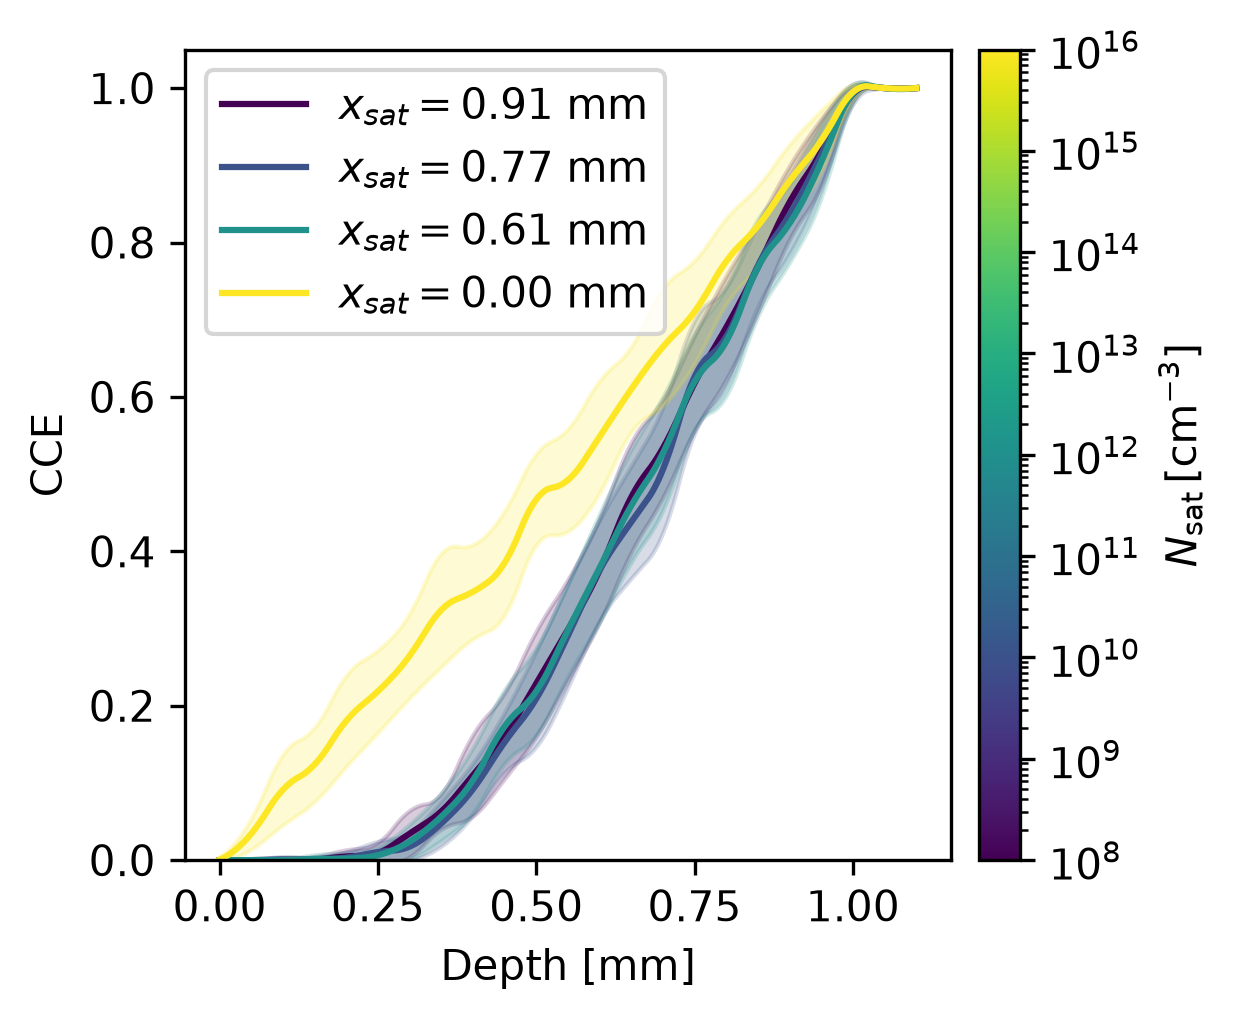

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import interp1d
import argparse

# ============================================================
# N_sat VALUES
# ============================================================

pow = np.arange(12, 17, 1)
pow = np.array([8, 10, 12, 16])
N_sats = 10 ** pow

cmap = plt.colormaps["viridis"]

norm = mpl.colors.LogNorm(
    vmin=N_sats.min(),
    vmax=N_sats.max()
)


histograms = {}
CCE_dict = {}

fig, ax = plt.subplots(
    figsize=(4.2, 3.5),
    dpi=300
)

# ============================================================
# LOOP OVER N_sat
# ============================================================

for i, N_sat in enumerate(N_sats):

    my_args = argparse.Namespace(
        seed=int(123),
        N_charges=150,
        N_repeat=150,
        alpha=4e-9,
        FCCD=0.1,
        sigma_R=0.002,
        N_sat=N_sat,
        T_ann=475,  # 200 °C
        t_ann=4*60*60,
        output="library"
    )

    params = simulate_CCE_Li_radii.update_parameters(my_args)

    cells, saturation_depth, px, py, pz, particles_R, lithium_distribution = (
        simulate_CCE_Li_radii.generate_lithium(params)
    )

    print(rf"$N_{{\mathrm{{sat}}}} = 10^{{{int(np.log10(N_sat))}}}$")
    print("seed =", my_args.seed)
    print("Numero Li:", len(px))
    print("Profondità saturazione:", saturation_depth * 10, "mm")

    x, CCE_matrix, CCE_mean, CCE_std = (
        simulate_CCE_Li_radii.simulate_CCE(
            cells,
            saturation_depth,
            px,
            py,
            pz,
            particles_R,
            my_args
        )
    )

    CCE_min = np.min(CCE_matrix, axis=1)
    CCE_max = np.max(CCE_matrix, axis=1)

    cce_min = np.array(CCE_min)
    cce_max = np.array(CCE_max)

    # INTERPOLATION
    depth = np.array(x) * 10
    cce = CCE_mean
    cce_std = CCE_std

    cce_interp = interp1d(
        depth,
        cce,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce[0], 1.0)
    )

    cce_min_interp = interp1d(
        depth,
        cce_min,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_min[0], 1.0)
    )

    cce_max_interp = interp1d(
        depth,
        cce_max,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_max[0], 1.0)
    )

    cce_std_interp = interp1d(
        depth,
        cce_std,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_std[0], cce_std[-1])
    )

    depth_fine = np.linspace(
        depth.min(),
        1.1,
        500
    )

    cce_fine = cce_interp(depth_fine)
    cce_std_fine = cce_std_interp(depth_fine)

    # Colore associato direttamente a N_sat
    color = cmap(norm(N_sat))

    # Legenda elegante in LaTeX
    label = rf"$N_{{\mathrm{{sat}}}} = 10^{{{int(np.log10(N_sat))}}}$"
    label = rf"$x_{{sat}} = {saturation_depth*10:.2f}$ mm"

    ax.plot(
        depth_fine,
        cce_fine,
        color=color,
        label=label
    )

    ax.fill_between(
        depth_fine,
        cce_fine - cce_std_fine,
        cce_fine + cce_std_fine,
        color=color,
        alpha=0.2
    )

    ax.legend(loc='upper left')

    # =========================
    # SPECTRA
    # =========================

    energy_bulk = make_spectrum(
        data_bulk,
        cce_interp,
        cce_std_interp
    )

    energy_surface = make_spectrum(
        data_surface_n,
        cce_interp,
        cce_std_interp
    )

    bin_edges = np.linspace(0, 3500, 700)

    counts_bulk, _ = np.histogram(
        energy_bulk,
        bins=bin_edges
    )

    counts_surface, _ = np.histogram(
        energy_surface,
        bins=bin_edges
    )

    spectrum_bulk = counts_bulk
    spectrum_surface = counts_surface

    spectrum_tot = spectrum_bulk + spectrum_surface
    
    histograms[N_sat] = (
        spectrum_tot,
        bin_edges
    )

    CCE_dict[N_sat] = (
        depth_fine,
        cce_fine
    )

# ============================================================
# COLORBAR
# ============================================================

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.03
)

cbar.set_label(r"$N_{\mathrm{sat}}\,[\mathrm{cm}^{-3}]$")

# ============================================================
# AXES
# ============================================================

ax.set_xlabel("Depth [mm]")
ax.set_ylabel("CCE")

ax.set_ylim(0, 1.05)

fig.tight_layout()

plt.show()


/tmp/ipykernel_1852655/4036630695.py:113: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


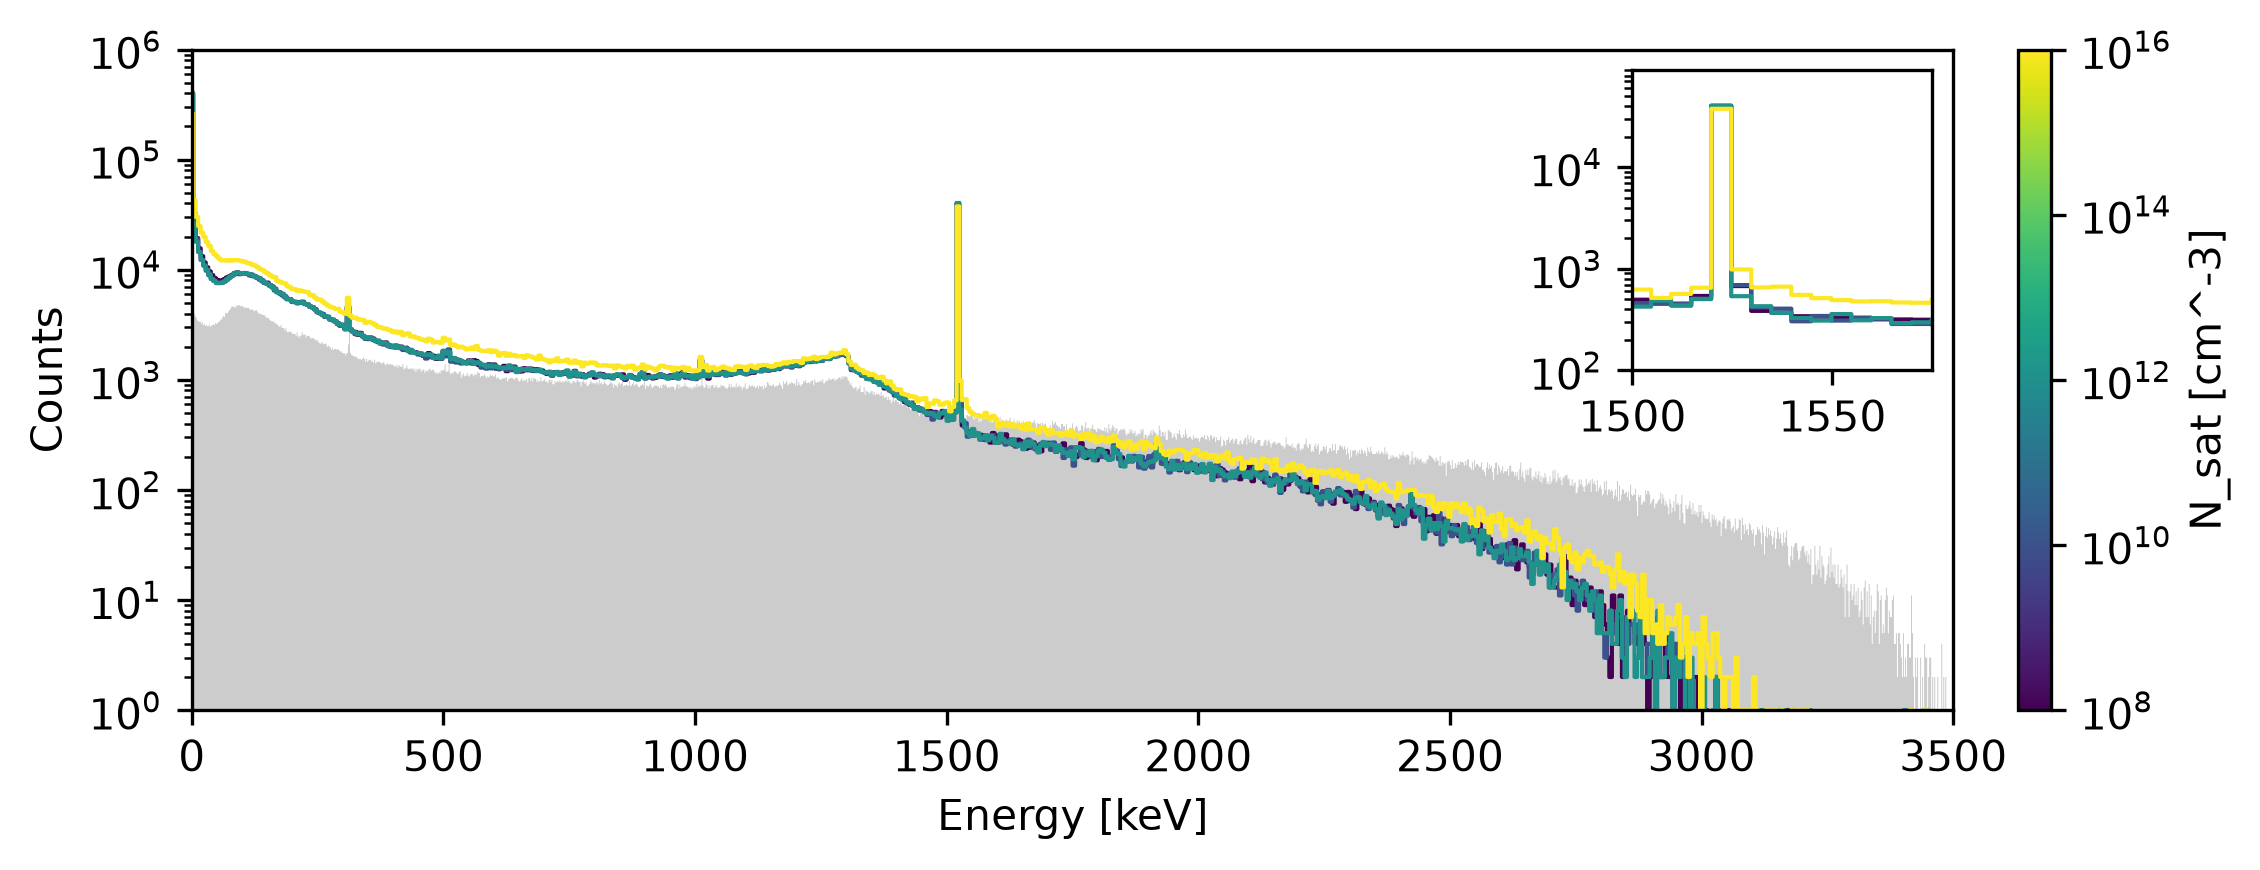

In [44]:
import matplotlib as mpl

fig, ax = plt.subplots(
    figsize=(8, 3),
    dpi=300
)

# ============================================================
# COLORMAP FCCD
# ============================================================

cmap = plt.colormaps["viridis"]

norm = mpl.colors.LogNorm(
    vmin=N_sats.min(),
    vmax=N_sats.max()
)


# ============================================================
# SPETTRI TOTALI PER FCCD
# ============================================================

for N_sat, (counts, edges) in histograms.items():

    color = cmap(
        norm(N_sat)
    )

    ax.step(
        edges[:-1],
        counts,
        where="mid",
        color=color,
        linewidth=1
    )


# ============================================================
# COLORBAR
# ============================================================

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.03
)

cbar.set_label("N_sat [cm^-3]")

plt.stairs(
    h_sum,
    bg,
    fill = True,
    label="LAr + surface",
    color = 'grey',
    alpha = 0.4)
# ============================================================
# PLOT SETTINGS
# ============================================================
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ============================================================
# INSET ZOOM AROUND 1525 keV
# ============================================================

axins = inset_axes(
    ax,
    width=1,   # dimensione relativa
    height=1,
    loc="upper right"
)

# Range di zoom
E_min = 1500
E_max = 1575

# Plot degli spettri FCCD dentro lo zoom
for N_sat, (counts, edges) in histograms.items():
    color = cmap(norm(N_sat))
    axins.step(
        edges[:-1],
        counts,
        where="mid",
        color=color,
        linewidth=1.0
    )



# Impostazioni zoom
axins.set_xlim(E_min, E_max)
axins.set_ylim(100, 9e4)   # puoi adattarlo se vuoi
axins.set_yscale("log")

#axins.set_xticks([1500, 1525, 1550, 1570])



ax.set_yscale("log")

ax.set_xlabel("Energy [keV]")
ax.set_ylabel("Counts")
ax.set_ylim(1, 1e6)
ax.set_xlim(0, 3500)
fig.tight_layout()

plt.show()

# alpha role

In [45]:
pow = np.arange(-13, -5, 4)
n = 10.0 ** pow
n

array([1.e-13, 1.e-09])

Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 158275.62it/s]


0.002 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 28001.62it/s]



Total theoretical primary Li (R=20 um) = 77
Total theoretical agglomerates = 77
Total theoretical remaining 20 um particles = 0
Total accepted agglomerates = 77
Total accepted remaining 20 um particles = 0
Total accepted Li particles = 77
${\alpha} = 10^{-12}$
seed = 123
Numero Li: 77
Profondità saturazione: 0.66 mm

Starting CCE simulation...



CCE depth: 100%|██████████| 23/23 [01:18<00:00,  3.41s/it]


...

0.002 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:01<00:00, 33.31it/s]



Total theoretical primary Li (R=20 um) = 27983
Total theoretical agglomerates = 707
Total theoretical remaining 20 um particles = 1903
Total accepted agglomerates = 588
Total accepted remaining 20 um particles = 1903
Total accepted Li particles = 2491
${\alpha} = 10^{-9}$
seed = 123
Numero Li: 2491
Profondità saturazione: 0.66 mm

Starting CCE simulation...



CCE depth: 100%|██████████| 23/23 [02:28<00:00,  6.48s/it]


$[\alpha] = 10^{-9}$


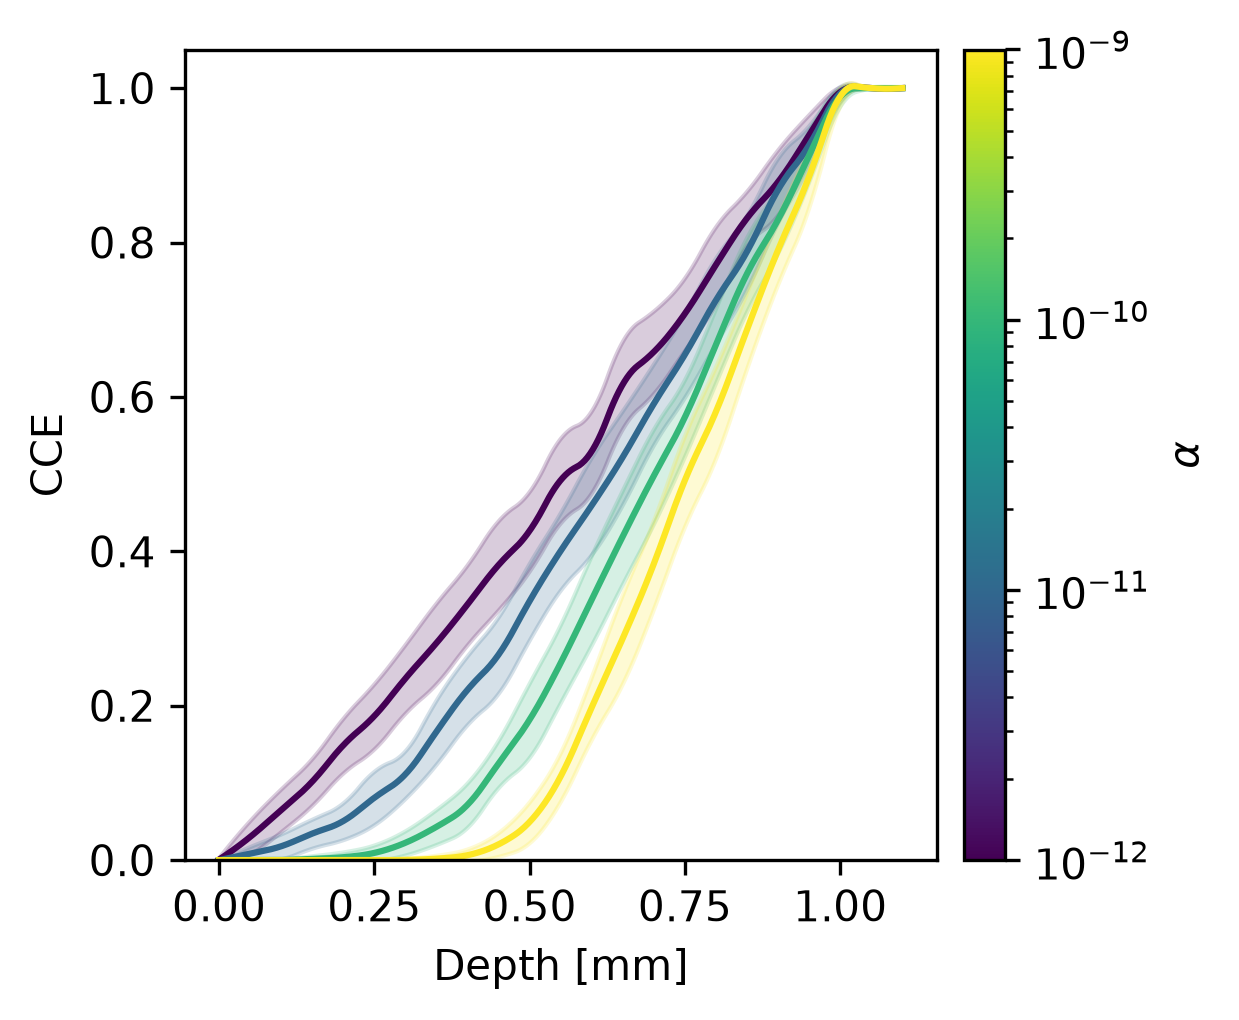

In [48]:
# ============================================================
# N_sat VALUES
# ============================================================

pow = np.arange(-13, -7, 1)
pow = np.arange(-12, -8, 1)
alphas = 10.0 ** pow

cmap = plt.colormaps["viridis"]

norm = mpl.colors.LogNorm(
    vmin=alphas.min(),
    vmax=alphas.max()
)


histograms = {}
CCE_dict = {}

fig, ax = plt.subplots(
    figsize=(4.2, 3.5),
    dpi=300
)

# ============================================================
# LOOP OVER N_sat
# ============================================================

for i, alpha in enumerate(alphas):

    my_args = argparse.Namespace(
        seed=int(123),
        N_charges=80,
        N_repeat=80,
        alpha=alpha,
        FCCD=0.1,
        sigma_R=0.002,
        N_sat=1e14,
        T_ann=623,  # 200 °C
        t_ann=18*60,
        output="library"
    )

    params = simulate_CCE_Li_radii.update_parameters(my_args)

    cells, saturation_depth, px, py, pz, particles_R, lithium_distribution = (
        simulate_CCE_Li_radii.generate_lithium(params)
    )

    print(rf"${{\alpha}} = 10^{{{int(np.log10(alpha))}}}$")
    print("seed =", my_args.seed)
    print("Numero Li:", len(px))
    print("Profondità saturazione:", saturation_depth * 10, "mm")

    x, CCE_matrix, CCE_mean, CCE_std = (
        simulate_CCE_Li_radii.simulate_CCE(
            cells,
            saturation_depth,
            px,
            py,
            pz,
            particles_R,
            my_args
        )
    )

    CCE_min = np.min(CCE_matrix, axis=1)
    CCE_max = np.max(CCE_matrix, axis=1)

    cce_min = np.array(CCE_min)
    cce_max = np.array(CCE_max)

    # INTERPOLATION
    depth = np.array(x) * 10
    cce = CCE_mean
    cce_std = CCE_std

    cce_interp = interp1d(
        depth,
        cce,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce[0], 1.0)
    )

    cce_min_interp = interp1d(
        depth,
        cce_min,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_min[0], 1.0)
    )

    cce_max_interp = interp1d(
        depth,
        cce_max,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_max[0], 1.0)
    )

    cce_std_interp = interp1d(
        depth,
        cce_std,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_std[0], cce_std[-1])
    )

    depth_fine = np.linspace(
        depth.min(),
        1.1,
        500
    )

    cce_fine = cce_interp(depth_fine)
    cce_std_fine = cce_std_interp(depth_fine)

    # Colore associato direttamente a N_sat
    color = cmap(norm(alpha))

    # Legenda elegante in LaTeX
    print(rf"$[\alpha] = 10^{{{int(np.log10(alpha))}}}$")
    #label = rf"$x_{{sat}} = {saturation_depth*10:.2f} mm$"

    ax.plot(
        depth_fine,
        cce_fine,
        color=color,
        #label=label
    )

    ax.fill_between(
        depth_fine,
        cce_fine - cce_std_fine,
        cce_fine + cce_std_fine,
        color=color,
        alpha=0.2
    )

    #ax.legend(loc='upper left')

    # =========================
    # SPECTRA
    # =========================

    energy_bulk = make_spectrum(
        data_bulk,
        cce_interp,
        cce_std_interp
    )

    energy_surface = make_spectrum(
        data_surface_n,
        cce_interp,
        cce_std_interp
    )

    bin_edges = np.linspace(0, 3500, 700)

    counts_bulk, _ = np.histogram(
        energy_bulk,
        bins=bin_edges
    )

    counts_surface, _ = np.histogram(
        energy_surface,
        bins=bin_edges
    )

    spectrum_bulk = counts_bulk
    spectrum_surface = counts_surface

    spectrum_tot = spectrum_bulk + spectrum_surface
    
    histograms[alpha] = (
        spectrum_tot,
        bin_edges
    )

    CCE_dict[alpha] = (
        depth_fine,
        cce_fine
    )

# ============================================================
# COLORBAR
# ============================================================

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.03
)

cbar.set_label(r"$\alpha$")

# ============================================================
# AXES
# ============================================================

ax.set_xlabel("Depth [mm]")
ax.set_ylabel("CCE")

ax.set_ylim(0, 1.05)

fig.tight_layout()

plt.show()


/tmp/ipykernel_1025806/2759616291.py:113: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


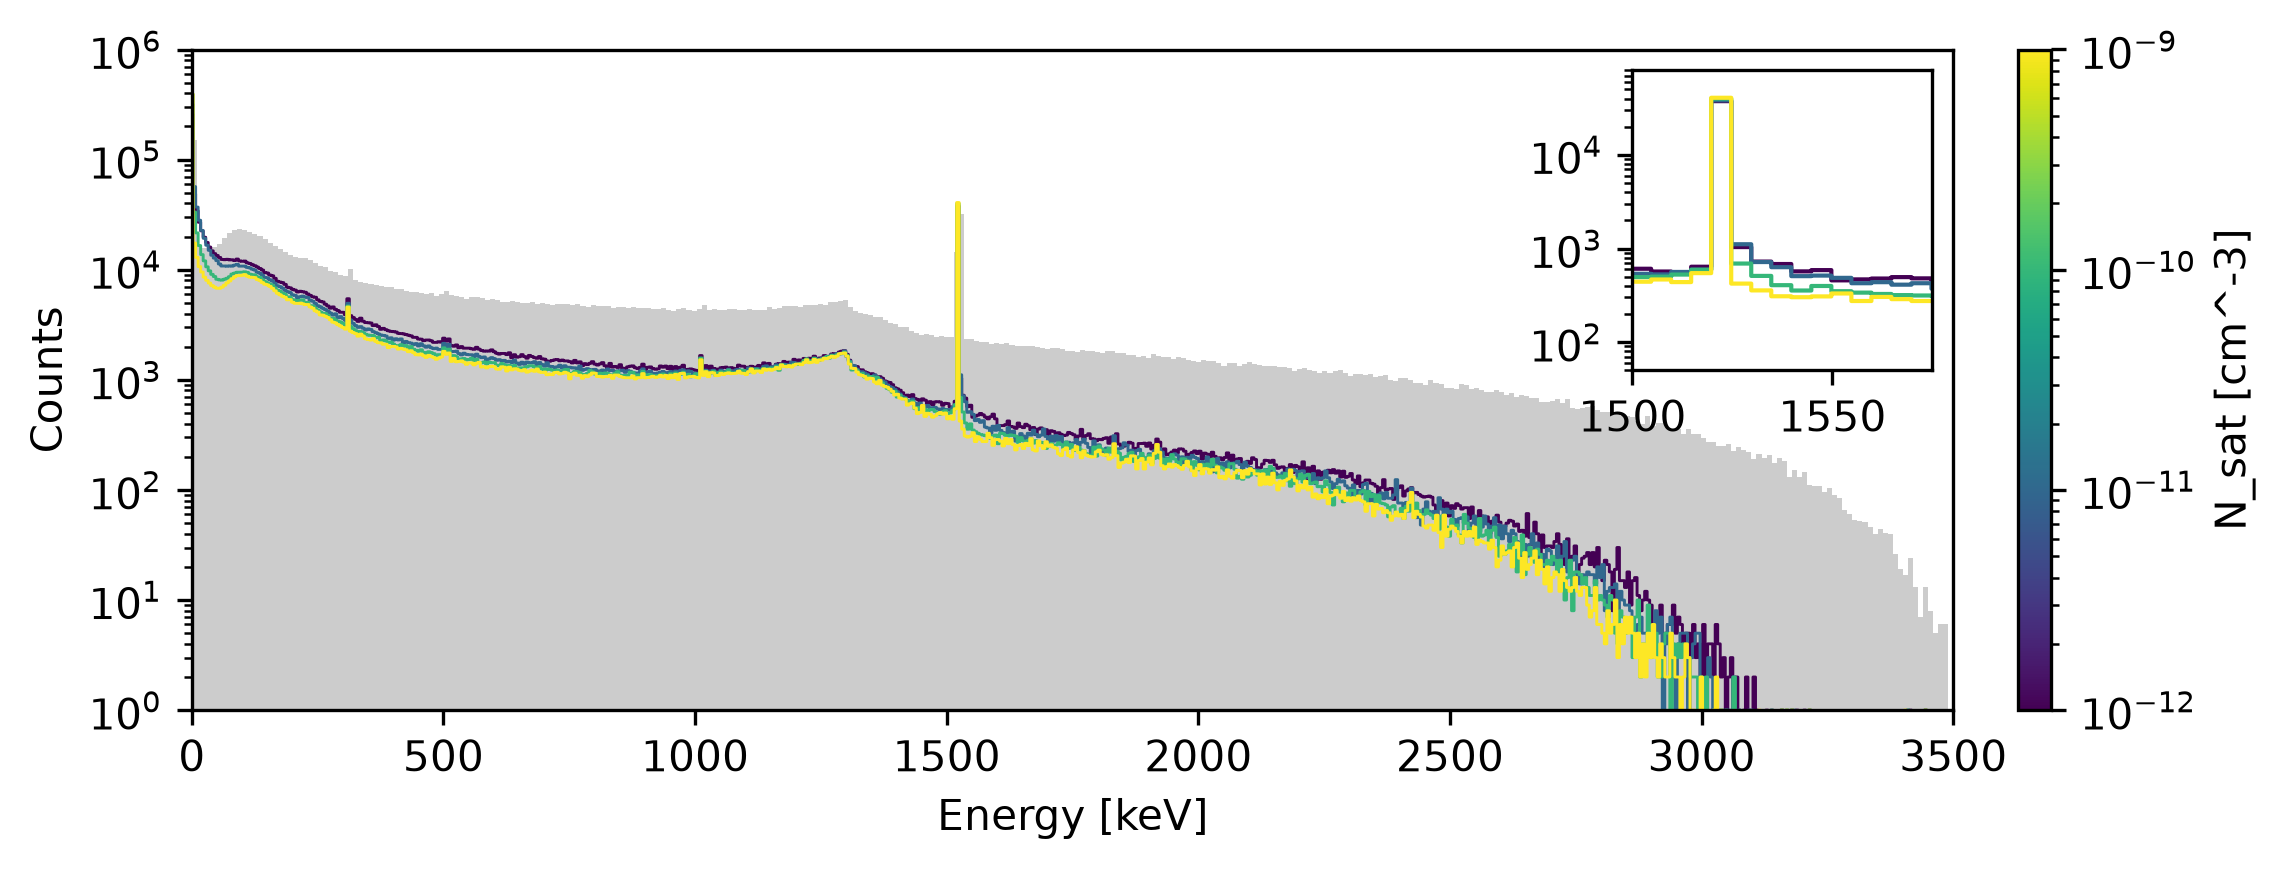

In [71]:
import matplotlib as mpl

fig, ax = plt.subplots(
    figsize=(8, 3),
    dpi=300
)

# ============================================================
# COLORMAP FCCD
# ============================================================

cmap = plt.colormaps["viridis"]

norm = mpl.colors.LogNorm(
    vmin=alphas.min(),
    vmax=alphas.max()
)


# ============================================================
# SPETTRI TOTALI PER FCCD
# ============================================================

for alpha, (counts, edges) in histograms.items():

    color = cmap(
        norm(alpha)
    )

    ax.step(
        edges[:-1],
        counts,
        where="mid",
        color=color,
        linewidth=0.7
    )


# ============================================================
# COLORBAR
# ============================================================

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.03
)

cbar.set_label("N_sat [cm^-3]")

plt.stairs(
    h_sum,
    bg,
    fill = True,
    label="LAr + surface",
    color = 'grey',
    alpha = 0.4)
# ============================================================
# PLOT SETTINGS
# ============================================================
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ============================================================
# INSET ZOOM AROUND 1525 keV
# ============================================================

axins = inset_axes(
    ax,
    width=1,   # dimensione relativa
    height=1,
    loc="upper right"
)

# Range di zoom
E_min = 1500
E_max = 1575

# Plot degli spettri FCCD dentro lo zoom
for alpha, (counts, edges) in histograms.items():
    color = cmap(norm(alpha))
    axins.step(
        edges[:-1],
        counts,
        where="mid",
        color=color,
        linewidth=1.0
    )



# Impostazioni zoom
axins.set_xlim(E_min, E_max)
axins.set_ylim(50, 8e4)   # puoi adattarlo se vuoi
axins.set_yscale("log")

#axins.set_xticks([1500, 1525, 1550, 1570])



ax.set_yscale("log")

ax.set_xlabel("Energy [keV]")
ax.set_ylabel("Counts")
ax.set_ylim(1, 1e6)
ax.set_xlim(0, 3500)
fig.tight_layout()

plt.show()

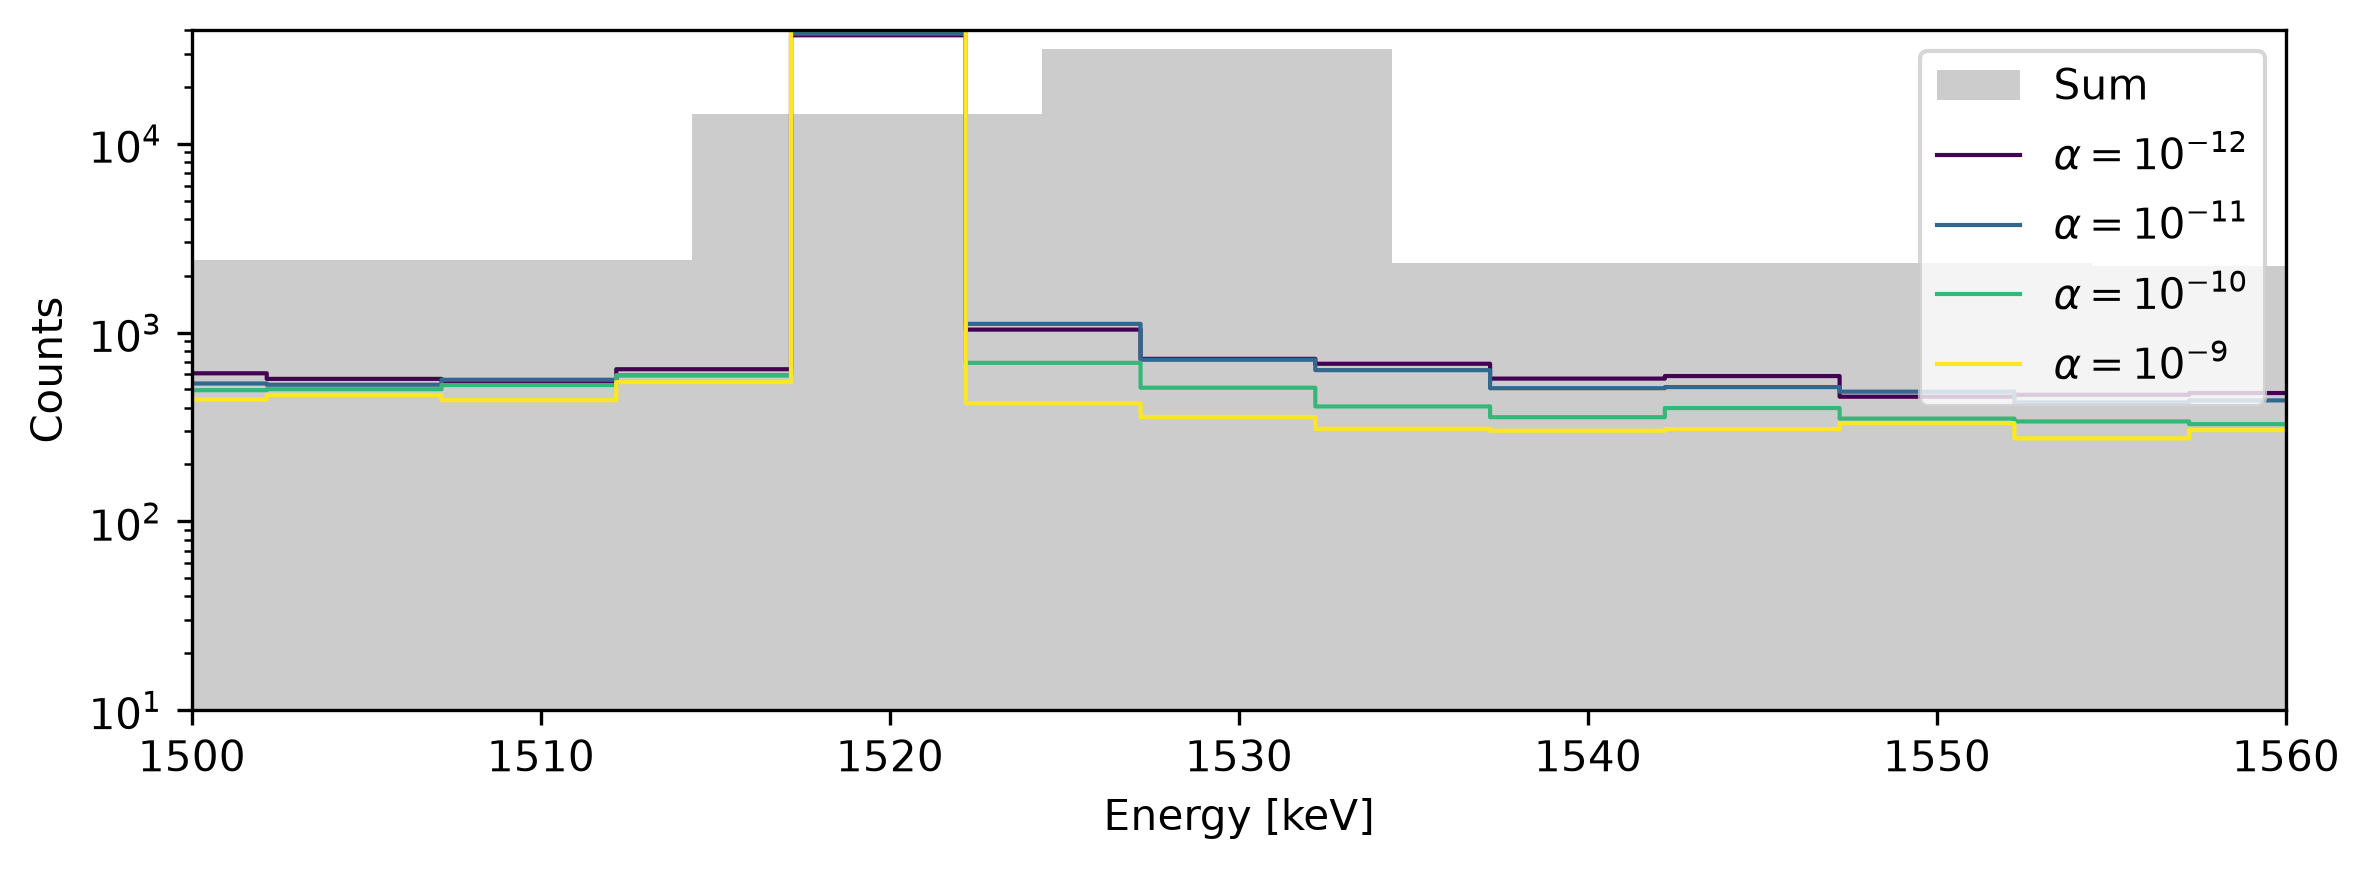

In [72]:
import matplotlib as mpl

fig, ax = plt.subplots(
    figsize=(8, 3),
    dpi=300
)

# ============================================================
# COLORMAP FCCD
# ============================================================

cmap = plt.colormaps["viridis"]

norm = mpl.colors.LogNorm(
    vmin=alphas.min(),
    vmax=alphas.max()
)
plt.stairs(
    h_sum,
    bg,
    color='grey',
    fill = True,
    label="Sum",
    alpha =0.4
)

# ============================================================
# SPETTRI TOTALI PER FCCD
# ============================================================

for alpha, (counts, edges) in histograms.items():

    color = cmap(
        norm(alpha)
    )

    ax.step(
        edges[:-1],
        counts,
        #where="mid",
        color=color,
        linewidth=1,
        label = rf"$\alpha = 10^{{{int(np.log10(alpha))}}}$"
    )


plt.yscale("log")
plt.legend()
ax.set_xlabel("Energy [keV]")
ax.set_ylabel("Counts")
ax.set_ylim(10, 4e4)
ax.set_xlim(1500, 1560)
fig.tight_layout()

plt.show()

# 1525 keV peak

In [2]:
from matplotlib.ticker import MultipleLocator
from matplotlib.ticker import AutoMinorLocator

In [24]:

my_args = argparse.Namespace(
        seed=int(123),
        N_charges=250,
        N_repeat=250,
        alpha=1.6e-11,
        FCCD=0.1,
        sigma_R=0.012,
        N_sat=1e14,
        #T_ann=475,  # 200 °C
        #t_ann=4*60*60,
        T_ann=623,  # 200 °C
        t_ann=18*60,
        output="library"
    )

params = simulate_CCE_Li_radii.update_parameters(my_args)

cells, saturation_depth, px, py, pz, particles_R, lithium_distribution = (
        simulate_CCE_Li_radii.generate_lithium(params)
    )

#print(rf"alpha = $10^{{{int(np.log10(alpha))}}}$")
print("seed =", my_args.seed)
print("Numero Li:", len(px))
print("Profondità saturazione:", saturation_depth * 10, "mm")

x, CCE_matrix, CCE_mean, CCE_std = (
        simulate_CCE_Li_radii.simulate_CCE(
            cells,
            saturation_depth,
            px,
            py,
            pz,
            particles_R,
            my_args
        )
    )

CCE_min = np.min(CCE_matrix, axis=1)
CCE_max = np.max(CCE_matrix, axis=1)

cce_min = np.array(CCE_min)
cce_max = np.array(CCE_max)

    # INTERPOLATION
depth = np.array(x) * 10
cce = CCE_mean
cce_std = CCE_std

depth_fine = np.linspace(
    depth.min(),
    1.1,
    1000,
)

cce_interp = interp1d(
        depth,
        cce,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce[0], 1.0)
    )

cce_min_interp = interp1d(
        depth,
        cce_min,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_min[0], 1.0)
    )

cce_max_interp = interp1d(
        depth,
        cce_max,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_max[0], 1.0)
    )

cce_std_interp = interp1d(
        depth,
        cce_std,
        kind="quadratic",
        bounds_error=False,
        fill_value=(cce_std[0], cce_std[-1])
    )

cce_fine = np.asarray(cce_interp(depth_fine))
cce_std_fine = np.maximum(
    np.asarray(cce_std_interp(depth_fine)),
    0.0,
)


Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 179639.24it/s]


0.012 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 3934.62it/s]



Total theoretical primary Li (R=20 um) = 1327
Total theoretical agglomerates = 492
Total theoretical remaining 20 um particles = 37
Total accepted agglomerates = 492
Total accepted remaining 20 um particles = 37
Total accepted Li particles = 529
seed = 123
Numero Li: 529
Profondità saturazione: 0.66 mm

Starting CCE simulation...



CCE depth: 100%|██████████| 23/23 [13:17<00:00, 34.67s/it]


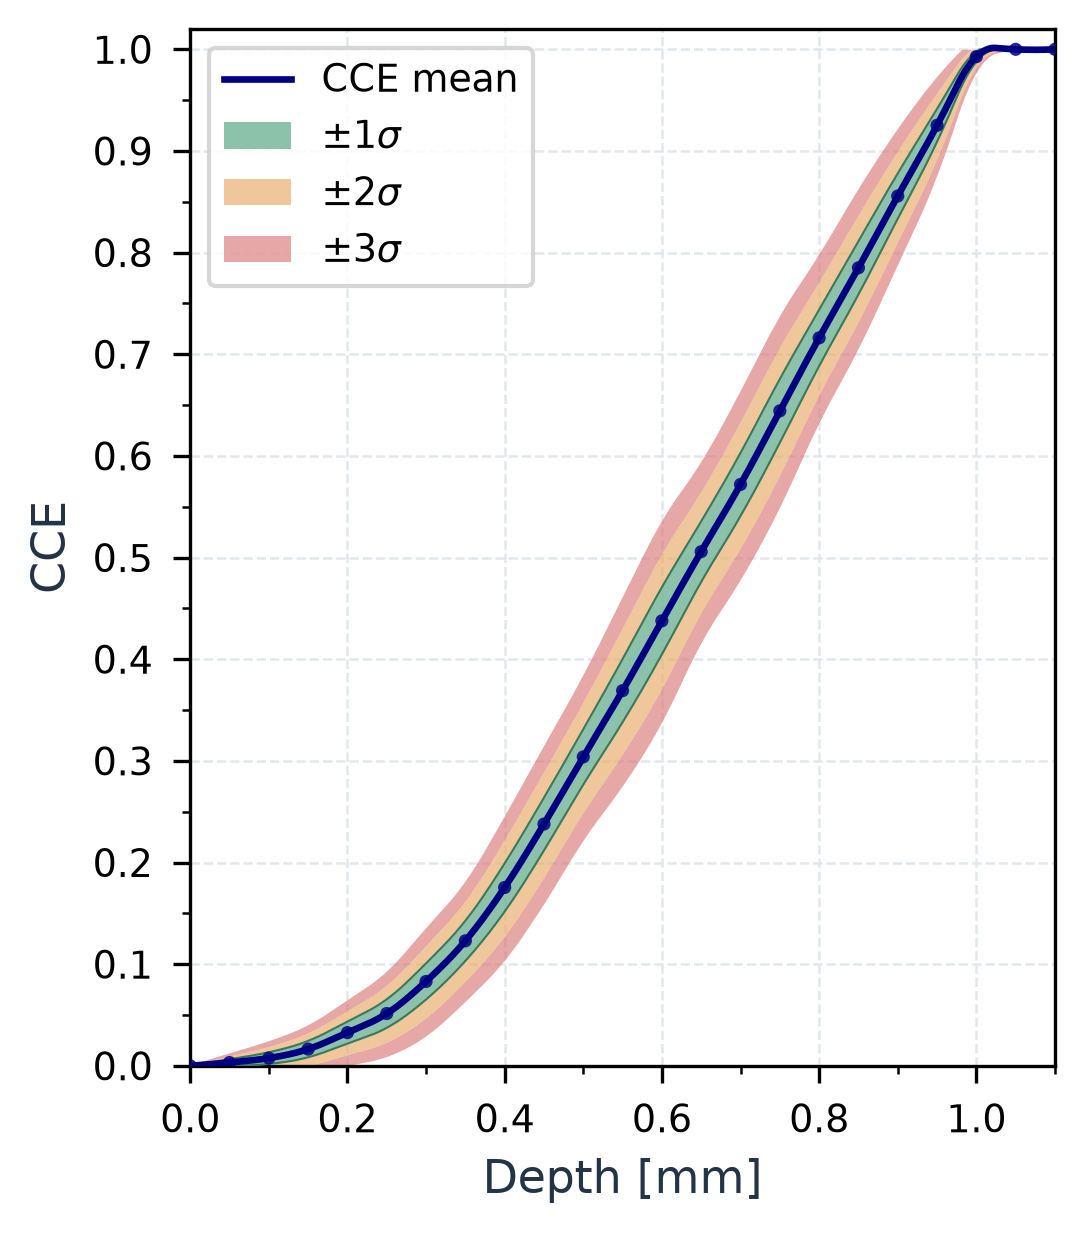

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import (
    MultipleLocator,
    AutoMinorLocator,
    MaxNLocator,
)

with plt.rc_context({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.8,
    #"text.color": "#243447",
    "axes.labelcolor": "#243447",
    #"xtick.color": "#526170",
    #"ytick.color": "#526170",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, ax = plt.subplots(
        figsize=(3.5, 4),
        dpi=300,
        layout="constrained",
    )

    # ========================================================
    # BANDS
    # ========================================================

    band_handles = {}
# ========================================================
# BANDS: FASCE SEPARATE, SENZA SOVRAPPOSIZIONI
# ========================================================

band_handles = {}

lower = {
    n: np.clip(cce_fine - n * cce_std_fine, 0, 1)
    for n in (1, 2, 3)
}

upper = {
    n: np.clip(cce_fine + n * cce_std_fine, 0, 1)
    for n in (1, 2, 3)
}

# Fascia centrale: entro 1 sigma
band_handles[1] = ax.fill_between(
    depth_fine,
    lower[1],
    upper[1],
    color="#79B89B",
    alpha=0.85,
    linewidth=0,
    label=r"$\pm 1\sigma$",
    zorder=2,
)

# Fasce esterne: 1–2 sigma e 2–3 sigma
for n, color in [
    (2, "#E9AA65"),
    (3, "#D97878"),
]:
    band_handles[n] = ax.fill_between(
        depth_fine,
        lower[n],
        lower[n - 1],
        color=color,
        alpha=0.65,
        linewidth=0,
        label=rf"$\pm {n}\sigma$",
        zorder=2,
    )

    ax.fill_between(
        depth_fine,
        upper[n - 1],
        upper[n],
        color=color,
        alpha=0.65,
        linewidth=0,
        zorder=2,
    )

# Contorni sottili per separare chiaramente le fasce
for n, color in [
    (1, "#39785B"),
    (2, "#AD722C"),
    (3, "#A34848"),
]:
    ax.plot(
        depth_fine, lower[n],
        color=color, linewidth=0.5, zorder=3,
    )
    ax.plot(
        depth_fine, upper[n],
        color=color, linewidth=0.5, zorder=3,
    )

    # ========================================================
    # MEAN CURVE
    # ========================================================

    mean_line, = ax.plot(
        depth_fine,
        cce_fine,
        color="navy",
        linewidth=1.6,
        label="CCE mean",
        zorder=5,
    )

    # ========================================================
    # AXES AND TICKS
    # ========================================================

    ax.set(
        xlabel="Depth [mm]",
        ylabel="CCE",
        xlim=(depth_fine.min(), depth_fine.max()),
        ylim=(0, 1.02),
    )

    ax.scatter(
    depth,
    cce,
    color="navy",
    s=10,
    edgecolors="none",
    alpha=0.85,
    zorder=6,
        )

    # Poche etichette x per evitare sovrapposizioni
    ax.xaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_major_locator(MultipleLocator(0.1))

    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

    ax.tick_params(
        which="major",
        direction="out",
        length=4,
        width=0.8,
        #color="#94A3B0",
        pad=5,
    )

    ax.tick_params(
        which="minor",
        direction="out",
        length=2,
        width=0.6,
        #color="#94A3B0",
    )




    # Solo griglia principale, dietro le bande
    ax.set_axisbelow(True)
    ax.grid(
        which="major",
        color="#E2E7EC",
        linewidth=0.6,
        linestyle="--",
    )

    # ========================================================
    # LEGEND
    # ========================================================

    ax.legend(
        handles=[
            mean_line,
            band_handles[1],
            band_handles[2],
            band_handles[3],
        ],
        loc="upper left",
        fontsize=9,
        handlelength=1.8,
        labelspacing=0.5,
    )

    plt.show()


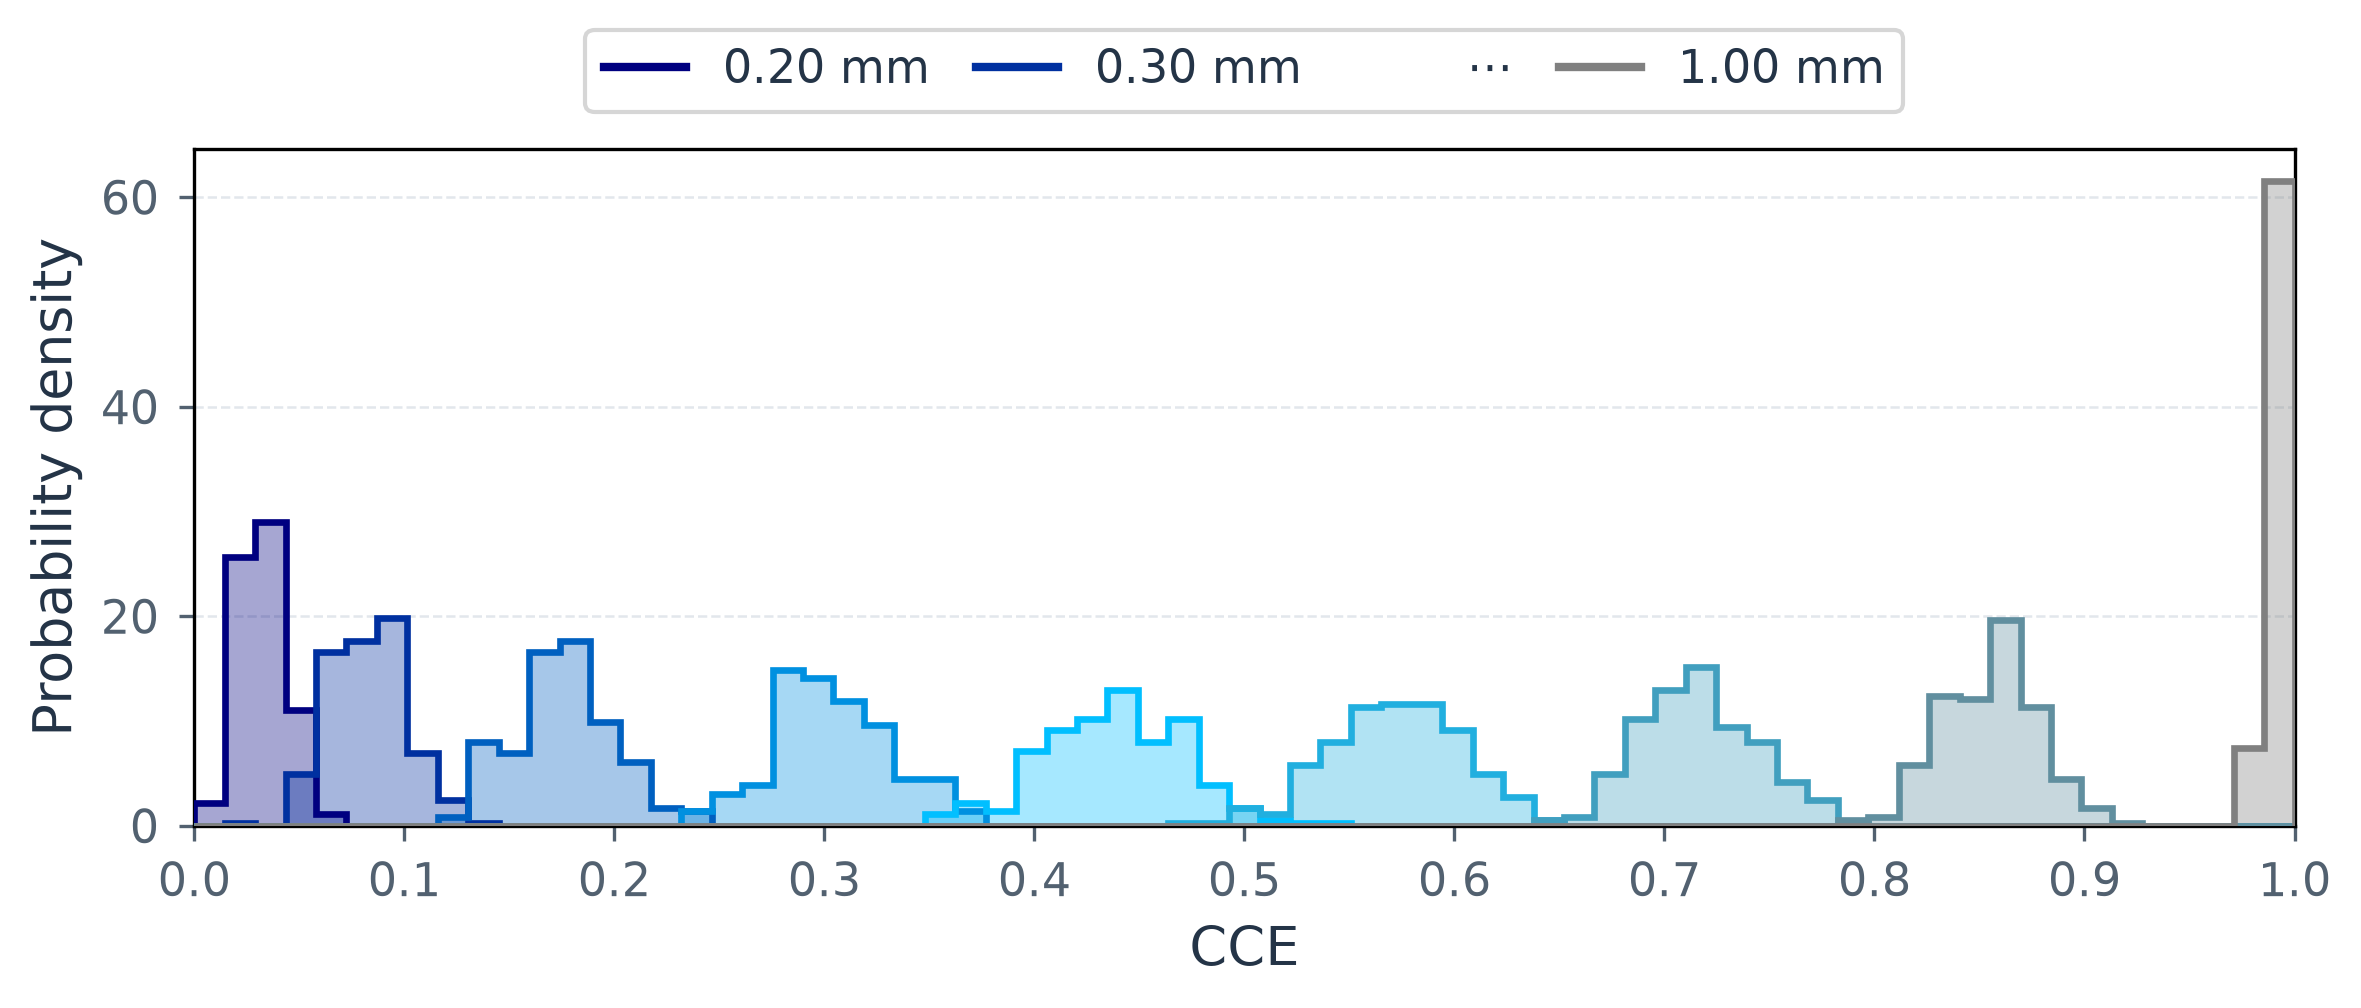

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from pathlib import Path

# ============================================================
# DEPTHS AND COLORS
# ============================================================

depth_indices = np.arange(4, 21, 2)
CCE_width = []

cmap = LinearSegmentedColormap.from_list(
    "presentation",
    ["navy", "deepskyblue", "grey"],
)

colors = cmap(np.linspace(0, 1, len(depth_indices)))

# Stessi bin per tutte le distribuzioni
bins = np.linspace(
    np.min(CCE_matrix),
    np.max(CCE_matrix),
    70,
)

# ============================================================
# FIGURE
# ============================================================

with plt.rc_context({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 0.8,
    "text.color": "#243447",
    "axes.labelcolor": "#243447",
    "xtick.color": "#526170",
    "ytick.color": "#526170",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
}):
    fig, ax = plt.subplots(
        figsize=(8, 3.5),
        dpi=300,
    )

    for k, i in enumerate(depth_indices):
        cce_dist = CCE_matrix[i, :]

        # Semidispersione massima
        cce_min = np.min(cce_dist)
        cce_max = np.max(cce_dist)
        semidispersione = (cce_max - cce_min) / 2

        CCE_width.append(semidispersione)

        # Riempimento leggero
        ax.hist(
            cce_dist,
            bins=bins,
            density=True,
            histtype="stepfilled",
            color=colors[k],
            edgecolor="none",
            alpha=0.35,
            zorder=2,
        )

        # Contorno della distribuzione
        ax.hist(
            cce_dist,
            bins=bins,
            density=True,
            histtype="step",
            color=colors[k],
            linewidth=1.6,
            zorder=3,
        )
        '''
        print(
            f"x = {x[i] * 10:.3f} mm"
            f" --> CCE mean = {CCE_mean[i]:.5f}"
            f" --> CCE min = {cce_min:.5f}"
            f" --> CCE max = {cce_max:.5f}"
            f" --> semidispersione = {semidispersione:.5f}"
        )'''

    CCE_width = np.asarray(CCE_width)

    # ========================================================
    # AXES
    # ========================================================

    ax.set(
        xlabel="CCE",
        ylabel="Probability density",
        xlim=(0, 1),
        ylim=(0, None),
    )

    ax.set_xticks(np.arange(0, 1.01, 0.1))
    ax.locator_params(axis="y", nbins=5)

    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color="#E2E7EC",
        linewidth=0.6,
        linestyle="--",
    )

    #ax.spines["top"].set_visible(False)
    #ax.spines["right"].set_visible(False)



    ax.tick_params(
        direction="out",
        length=3.5,
        width=0.8,
        #color="#94A3B0",
        pad=5,
    )

    ax.margins(y=0.08)

    # ========================================================
    # LEGEND: FIRST, SECOND, ..., LAST DEPTH
    # ========================================================
    
    legend_handles = [
        Line2D([], [], color=colors[0], linewidth=2),
        Line2D([], [], color=colors[1], linewidth=2),
        Line2D([], [], linestyle="none"),
        Line2D([], [], color=colors[-1], linewidth=2),
    ]

    legend_labels = [
        f"{x[depth_indices[0]] * 10:.2f} mm",
        f"{x[depth_indices[1]] * 10:.2f} mm",
        r"$\cdots$",
        f"{x[depth_indices[-1]] * 10:.2f} mm",
    ]

    ax.legend(
        legend_handles,
        legend_labels,
        #title="Depth",
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=4,
        frameon=True,
        fontsize=11,
        title_fontsize=11,
        handlelength=1.8,
        columnspacing=1,
    )

    # ========================================================
    # SAVE AND SHOW
    # ========================================================

    fig.tight_layout()

    Path("plot").mkdir(parents=True, exist_ok=True)

    fig.savefig(
        "plot/CCE_pdf.png",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.15,
    )

    plt.show()


In [21]:
# ============================
# Bin comuni
# ============================
bg = np.linspace(0, 3500, 3500)

# ============================
# Pesi corretti
# ============================
# Bulk: nessun peso → già rappresenta N_bulk eventi
weights_bulk = np.ones_like(energy_bulk_smeared)

# Surface: ogni evento deve valere N_bulk / N_surface
weights_surface = np.full(
    len(energy_surface_smeared),
    1
)

# ============================
# Istogrammi
# ============================
h_bulk, _ = np.histogram(
    energy_bulk_smeared,
    bins = bg,
    #weights = weights_bulk
)

h_surface, _ = np.histogram(
    energy_surface_smeared,
    bins = bg,
    #weights = weights_surface
)

# ============================
# Somma dei contributi
# ============================
h_sum = h_bulk + h_surface

# ============================
# Centri dei bin
# ============================
bin_centers = 0.5 * (bg[:-1] + bg[1:])
# Centri dei bin
# Plot
plt.figure(figsize=(6, 3), dpi = 300)

# Spettri con plt.step
plt.stairs(
    h_sum,
    bg,
    color='deepskyblue',
    fill = True,
    label="Sum",
    alpha =0.9
)
plt.stairs(
    spectrum_tot,
    bg,
    color='navy',
    #fill = True,
    label="CCE",
)


plt.yscale("log")

plt.xlabel("Energy [keV]")
plt.ylabel(f"Counts / {bg[1]-bg[0]:.1f} keV")
plt.ylim(20, 4e4)
plt.xlim(1500, 1560)

NameError: name 'energy_bulk_smeared' is not defined